# Feature Engineering and Model Training: BRFSS 2024 Cost-Related Barriers to Care

## 🗺️ Roadmap: read this first
This notebook follows the same idea as the visa project, but every step is **numbered in the order it must happen**.
Each step starts with a box that says **what** it does, **why it comes at that point**, and **what the data looks like afterwards** (rows × columns).

**The golden rule that decides the order:**
* **Steps 1–5** only use *each person's own row* (cleaning, counting their own conditions), so they can safely run on **all** the data.
* **Step 6 splits the data.** From then on, anything that *learns* from data (scaling, encoding, resampling, training, tuning) learns from the **training set only**.
* The **test set is the "final exam"**: it is used **once**, to measure performance (Step 17 onwards). It is never used to compare models or to choose features, settings or thresholds: Steps 12–16 and 22–24 do that with **cross-validation on the training data**.

```
PART 1 · FULL MODEL
 1 Load ─► 2 Clean ─► 3 Create new features ─► 4 Feature types ─► 5 Separate X / y
                                                                         │
 ┌───────────────────────────────────────────────────────────────────────┘
 ▼
 6 TRAIN / TEST SPLIT ─► 7 Check skew ─► 8 Encode & scale ─► 9 Development sample ─► 10 Handle imbalance
                                                                                          │
 ┌────────────────────────────────────────────────────────────────────────────────────────┘
 ▼
 11 Set up models ─► 12 Compare 9 models ─► 13 SMOTEENN vs class weights ─► 14 Tune ─► 15 Retrain tuned
                                                                                          │
 ┌────────────────────────────────────────────────────────────────────────────────────────┘
 ▼
 16 Choose final model ─► 17 FINAL EXAM ─► 18 Fairness ─► 19 Explain (SHAP) ─► 20 Save ─► 21 Predict 1 person

PART 2 · SHORT 12-QUESTION SCREENER
 22 Choose questions ─► 23 Weights or not ─► 24 Train + final exam ─► 25 Fairness ─► 26 SHAP ─► 27 Save + predict

 28 Conclusions ─► 29 BEST MODEL
```

| Step | What happens | Data after |
|---|---|---|
| 1 | Load the CSV | 455,997 × 43 |
| 2 | Clean: missing values, duplicates, drop non-predictor columns | 455,997 × 36 (35 inputs + target) |
| 3 | Create 2 new features (counts) | 455,997 × 38 (37 inputs + target) |
| 4 | Identify feature types | no change (35 categorical + 2 numeric) |
| 5 | Separate inputs X and target y | X 455,997 × 37, y 455,997 |
| 6 | **Train/test split** (80/20) | train 364,797 × 37 · test 91,200 × 37 |
| 7 | Check skewness of the numeric features | no change |
| 8 | Encode & scale (learn on train, apply to test) | train 364,797 × 160 · test 91,200 × 160 |
| 9 | Development sample for comparing/tuning | 60,000 × 160 |
| 10 | Imbalance: SMOTEENN (template method) | 84,987 × 160 (63.8% Yes) |
| 11 | Set up models and the scorecard | no change |
| 12 | Train and compare 9 models | model report |
| 13 | Compare SMOTEENN vs class weights | decision: class weights |
| 14 | Hyperparameter tuning (XGBoost, RF, KNN) | best settings |
| 15 | Retrain tuned models | tuned report |
| 16 | Choose final model, set threshold, retrain on all training rows | final model |
| 17 | **Final exam** on the test set | final scores |
| 18 | Fairness by group | subgroup table |
| 19 | Explain the model (SHAP) | top factors |
| 20 | Save the model | `.joblib` file |
| 21 | Predict for one person | risk + Yes/No |
| 22–27 | Part 2: the 12-question screener | short model |
| 28 | Conclusions | |
| 29 | **Best model** | |

# STEP 1 · Load the data
> **What:** Import the Python libraries and read `BRFSS2024_access.csv`.  
> **Why here:** Everything starts from the data.  
> **Data after this step:** **455,997 rows × 43 columns**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, time
warnings.filterwarnings("ignore")
pd.pandas.set_option("display.max_columns", None)
SEED = 42
# Create Dataframe
df = pd.read_csv(r"../data/BRFSS2024_access.csv", dtype={"children_in_household": str})
# Print shape of dataset
print(df.shape)

(455997, 43)


# STEP 2 · Data cleaning
> **What:** Check missing values and duplicates, and remove columns that must not be used as predictors.  
> **Why here:** We clean the table before creating anything new from it.  
> **Data after this step:** **455,997 rows × 36 columns** (35 inputs + 1 target)

### 2a · Missing values

* Handling Missing values
* Handling Duplicates
* Check data type
* Understand the dataset

#### Check Null Values

In [2]:
##these are the features with nan value
features_with_na=[features for features in df.columns if df[features].isnull().sum()>=1]
for feature in features_with_na:
    print(feature,np.round(df[feature].isnull().mean()*100,5), '% missing values')
features_with_na

[]

* **There are no null values.** Notebook 0 coded "Don't know/Refused" as `Unknown`; see the EDA for the Unknown shares.

### 2b · Duplicates

**Handling Duplicates**

In [3]:
df.duplicated().sum()

0

### 2c · Remove columns that cannot be used as predictors

**Remove columns that cannot be used as predictors**
* `seqno`: an ID (like `case_id` in the visa data).
* `survey_weight`, `strata`, `psu`: survey-design variables. They are kept *aside* for weighted evaluation, never used as features.
* `state`: 53 levels, summarised by `census_region` + `medicaid_expansion_state`.
* `has_personal_doctor`, `last_checkup`: **leakage risk**. They measure access to care themselves and can be a *consequence* of the outcome (see EDA).

In [4]:
design = df[['survey_weight', 'strata', 'psu']].copy()
df.drop(columns=['seqno', 'survey_weight', 'strata', 'psu', 'state', 'has_personal_doctor', 'last_checkup'], inplace=True)
df.shape

(455997, 36)

# STEP 3 · Feature engineering: create new features
> **What:** Combine several Yes/No columns into 2 new count columns: `n_disabilities` (from 6 columns) and `n_chronic_conditions` (from 9 columns).  
> **Why here:** Each new value uses **only that person's own answers**, so it is safe to do before the split, and both train and test get the new columns automatically.  
> **Data after this step:** **455,997 rows × 38 columns**: same rows, **2 new columns**

### 3a · BEFORE: the original columns we are going to combine

In [5]:
df.head()

,could_not_afford_doctor,census_region,medicaid_expansion_state,urban_rural,age_group,sex,race_ethnicity,education,income,employment,marital_status,home_ownership,veteran,children_in_household,insurance_type,general_health,physical_unhealthy_days,mental_unhealthy_days,bmi_category,smoking_status,physical_activity,diabetes,heart_disease,stroke,copd,depression,kidney_disease,arthritis,asthma,cancer_non_skin,hearing_difficulty,vision_difficulty,cognitive_difficulty,mobility_difficulty,selfcare_difficulty,independent_living_difficulty
0,No,South,No,Urban,75-79,Female,White NH,High school graduate,Unknown,Retired,Widowed,Own,No,0,Medicare,Good,1-13 days,0 days,Normal,Never,Yes,No,No,No,No,No,No,Yes,Never,No,No,No,No,No,No,No
1,No,South,No,Urban,80+,Male,White NH,College graduate,$200k+,Retired,Married,Own,Yes,0,Medicare,Excellent,0 days,0 days,Overweight,Former,Yes,No,Yes,No,No,No,No,Yes,Never,No,No,No,No,No,No,No
2,Yes,South,No,Urban,55-59,Male,White NH,Some college/technical,Unknown,Employed for wages,Unmarried couple,Own,Yes,0,Employer/union,Very good,14+ days,0 days,Normal,Current daily,Yes,No,No,No,No,No,No,Yes,Never,No,No,No,No,No,No,No
3,No,South,No,Urban,80+,Male,White NH,College graduate,$35k-<50k,Retired,Married,Own,No,0,Medicare,Excellent,0 days,0 days,Overweight,Never,Yes,No,No,No,No,No,No,Yes,Never,No,Yes,No,No,No,No,No
4,No,South,No,Urban,45-49,Male,White NH,Some college/technical,$15k-<25k,Unable to work,Never married,Own,No,0,Medicaid/CHIP/State,Good,0 days,0 days,Normal,Never,No,No,No,No,No,No,No,No,Never,No,Yes,No,No,Yes,No,Yes


In [6]:
chronic_cols = ['diabetes','heart_disease','stroke','copd','depression','kidney_disease','arthritis','asthma','cancer_non_skin']
dis_cols = ['hearing_difficulty','vision_difficulty','cognitive_difficulty','mobility_difficulty',
            'selfcare_difficulty','independent_living_difficulty']
print("Shape BEFORE feature engineering:", df.shape)
print("\nThe 6 disability columns (will become n_disabilities):")
df[dis_cols].head(8)

Shape BEFORE feature engineering: (455997, 36)

The 6 disability columns (will become n_disabilities):


,hearing_difficulty,vision_difficulty,cognitive_difficulty,mobility_difficulty,selfcare_difficulty,independent_living_difficulty
0,No,No,No,No,No,No
1,No,No,No,No,No,No
2,No,No,No,No,No,No
3,Yes,No,No,No,No,No
4,Yes,No,No,Yes,No,Yes
5,No,No,No,No,No,No
6,No,No,No,No,No,No
7,No,No,Yes,Yes,Yes,Yes


In [7]:
print("The 9 chronic-condition columns (will become n_chronic_conditions):")
df[chronic_cols].head(8)

The 9 chronic-condition columns (will become n_chronic_conditions):


,diabetes,heart_disease,stroke,copd,depression,kidney_disease,arthritis,asthma,cancer_non_skin
0,No,No,No,No,No,No,Yes,Never,No
1,No,Yes,No,No,No,No,Yes,Never,No
2,No,No,No,No,No,No,Yes,Never,No
3,No,No,No,No,No,No,Yes,Never,No
4,No,No,No,No,No,No,No,Never,No
5,Yes,No,No,No,No,No,No,Never,Yes
6,No,Yes,No,No,No,No,Yes,Never,Yes
7,Yes,No,Yes,Yes,No,No,Yes,Never,No


### 3b · Create the new features

**Create two count features**, the BRFSS equivalent of `company_age` in the visa project:
* `n_chronic_conditions`: number of conditions ever diagnosed (diabetes, heart disease, stroke, COPD, depression, kidney disease, arthritis, current asthma, non-skin cancer).
* `n_disabilities`: number of the 6 CDC disability types reported.

In [8]:
chronic = {'diabetes': 'Yes', 'heart_disease': 'Yes', 'stroke': 'Yes', 'copd': 'Yes', 'depression': 'Yes',
           'kidney_disease': 'Yes', 'arthritis': 'Yes', 'asthma': 'Current', 'cancer_non_skin': 'Yes'}
dis_cols = ['hearing_difficulty','vision_difficulty','cognitive_difficulty','mobility_difficulty',
            'selfcare_difficulty','independent_living_difficulty']
df['n_chronic_conditions'] = sum((df[c] == v).astype(int) for c, v in chronic.items())
df['n_disabilities'] = (df[dis_cols] == 'Yes').sum(axis=1)
df[['n_chronic_conditions', 'n_disabilities']].describe()

,n_chronic_conditions,n_disabilities
count,455997.000000,455997.000000
mean,1.198361,0.530510
std,1.323045,0.985292
min,0.000000,0.000000
25%,0.000000,0.000000
50%,1.000000,0.000000
75%,2.000000,1.000000
max,9.000000,6.000000


### 3c · AFTER: the new columns, shown next to the columns they were made from

In [9]:
print("Shape AFTER feature engineering:", df.shape, " -> same rows, 2 new columns")
df[dis_cols + ['n_disabilities']].head(8)

Shape AFTER feature engineering: (455997, 38)  -> same rows, 2 new columns


,hearing_difficulty,vision_difficulty,cognitive_difficulty,mobility_difficulty,selfcare_difficulty,independent_living_difficulty,n_disabilities
0,No,No,No,No,No,No,0
1,No,No,No,No,No,No,0
2,No,No,No,No,No,No,0
3,Yes,No,No,No,No,No,1
4,Yes,No,No,Yes,No,Yes,3
5,No,No,No,No,No,No,0
6,No,No,No,No,No,No,0
7,No,No,Yes,Yes,Yes,Yes,4


In [10]:
# a few people who DO have disabilities, so the counting is easy to check
df.loc[df['n_disabilities'] >= 2, dis_cols + ['n_disabilities']].head(5)

,hearing_difficulty,vision_difficulty,cognitive_difficulty,mobility_difficulty,selfcare_difficulty,independent_living_difficulty,n_disabilities
4,Yes,No,No,Yes,No,Yes,3
7,No,No,Yes,Yes,Yes,Yes,4
13,No,No,Yes,Yes,No,No,2
16,No,No,No,Yes,Yes,No,2
21,No,No,No,Yes,No,Yes,2


In [11]:
# a few people with several chronic conditions (asthma counts only if 'Current')
df.loc[df['n_chronic_conditions'] >= 3, chronic_cols + ['n_chronic_conditions']].head(5)

,diabetes,heart_disease,stroke,copd,depression,kidney_disease,arthritis,asthma,cancer_non_skin,n_chronic_conditions
6,No,Yes,No,No,No,No,Yes,Never,Yes,3
7,Yes,No,Yes,Yes,No,No,Yes,Never,No,4
9,Yes,Yes,No,No,No,No,Yes,Never,No,3
10,No,Yes,No,No,Yes,Yes,Yes,Never,No,4
11,No,No,Yes,No,No,No,Yes,Never,Yes,3


# STEP 4 · Identify feature types
> **What:** List which features are numeric and which are categorical.  
> **Why here:** All features now exist (including the new ones), and the type decides how each one is encoded in Step 8.  
> **Data after this step:** no change: **35 categorical + 2 numeric** features

**Numeric Features**

In [12]:
num_features = df.select_dtypes(include='number').columns.tolist()
print('Num of Numerical Features :', len(num_features), num_features)

Num of Numerical Features : 2 ['n_chronic_conditions', 'n_disabilities']


**Categorical Features**

In [13]:
cat_features = [c for c in df.select_dtypes(exclude='number').columns if c != 'could_not_afford_doctor']
print('Num of Categorical Features :', len(cat_features))

Num of Categorical Features : 35


**Discrete features**

In [14]:
discrete_features=[feature for feature in num_features if len(df[feature].unique())<=25]
print('Num of Discrete Features :',len(discrete_features))

Num of Discrete Features : 2


**Continues Features**

In [15]:
continuous_features=[feature for feature in num_features if feature not in discrete_features]
print('Num of Continuous Features :',len(continuous_features))

Num of Continuous Features : 0


* Both engineered features are **discrete counts** (0–9 and 0–6). There are no continuous features in BRFSS.

# STEP 5 · Separate inputs (X) and target (y)
> **What:** Put the 37 input features in `X` and the answer we predict in `y` (Yes = 1, No = 0).  
> **Why here:** The split in Step 6 needs X and y as separate pieces.  
> **Data after this step:** **X: 455,997 × 37**, **y: 455,997 values**

* **Split Dataframe to X and y**
* **Here we set a variable X i.e, independent columns, and a variable y i.e, dependent column as the “could_not_afford_doctor” column.**

In [16]:
X = df.drop('could_not_afford_doctor', axis=1)
y = df['could_not_afford_doctor']
y.head()

0     No
1     No
2    Yes
3     No
4     No
Name: could_not_afford_doctor, dtype: object

**Manual encoding target column**

In [17]:
# If the target column is Yes (could not afford a doctor) it is encoded as 1, others as 0
y = np.where(y == 'Yes', 1, 0)
y.mean()

0.09509492387011317

In [18]:
print('X shape:', X.shape, '| y shape:', y.shape)

X shape: (455997, 37) | y shape: (455997,)


# STEP 6 · Train / test split
> **What:** Set aside 20% of people as the **final exam** (test set). The other 80% is the training set. The split is *stratified*, so both keep the 9.5% Yes rate.  
> **Why here:** All steps that use only a person's own row are finished. **Everything after this point learns from data**, so it must only see the training set; otherwise information from the exam leaks into training.  
> **Data after this step:** **train: 364,797 × 37**, **test: 91,200 × 37**

* Stratified 80/20, so both parts keep the 9.5% "Yes" rate.
* Survey weights are split along with the rows, so the test set can be evaluated with weights.

In [19]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test, w_train, w_test = train_test_split(
    X, y, design['survey_weight'].values, test_size=0.2, random_state=SEED, stratify=y)
X_test_raw = X_test.copy()          # keep readable test rows for the fairness analysis
print(X_train.shape, X_test.shape, '| % Yes train/test:', round(y_train.mean()*100, 2), round(y_test.mean()*100, 2))

(364797, 37) (91200, 37) | % Yes train/test: 9.51 9.51


# STEP 7 · Check skewness of the numeric features
> **What:** Look at the distribution of the 2 count features and test whether a power transform makes them less skewed.  
> **Why here:** We decide how to transform numeric features *before* building the encoder in Step 8. It is checked on training data only.  
> **Data after this step:** no change (this step only checks)

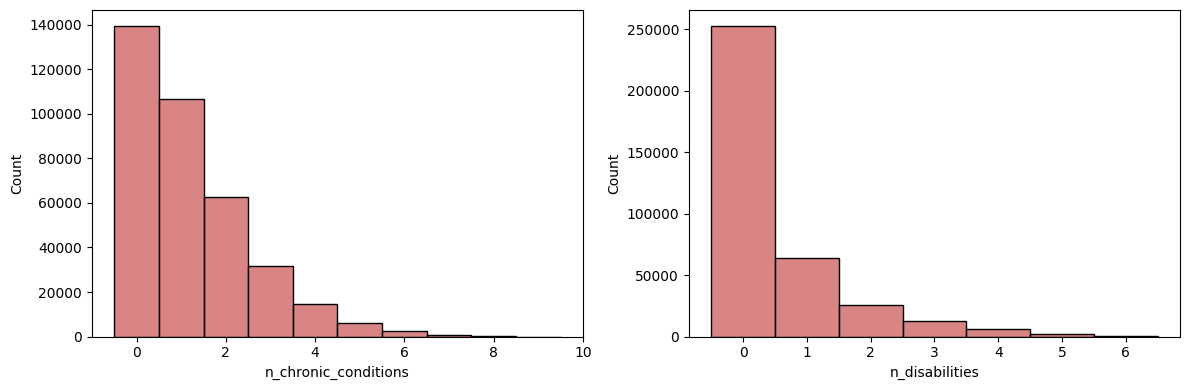

In [20]:
# distribution of the numeric (count) features before scaling — training data only
plt.figure(figsize=(12, 4))
for i, col in enumerate(num_features):
    plt.subplot(1, 2, i+1)
    sns.histplot(x=X_train[col], color='indianred', discrete=True)
    plt.xlabel(col)
    plt.tight_layout()

**Checking Skewness**

In [21]:
# Check Skewness
X_train[num_features].skew(axis=0, skipna=True)

n_chronic_conditions    1.302386
n_disabilities          2.259027
dtype: float64

## Apply Power Transformer to Check if it can reduces the skewness

In [22]:
from sklearn.preprocessing import PowerTransformer
pt = PowerTransformer(method='yeo-johnson')
X_copy = pd.DataFrame(pt.fit_transform(X_train[num_features]), columns=num_features)
X_copy.skew(axis=0, skipna=True)

n_chronic_conditions    0.079537
n_disabilities          0.862433
dtype: float64

- Yeo-Johnson reduces the skew of both counts, so we keep it, as in the visa template.

In [23]:
for feature in cat_features:
    print(feature,':', df[feature].nunique())

census_region : 5
medicaid_expansion_state : 3
urban_rural : 3
age_group : 14
sex : 2
race_ethnicity : 6
education : 5
income : 8
employment : 9
marital_status : 7
home_ownership : 4
veteran : 3
children_in_household : 7
insurance_type : 7
general_health : 6
physical_unhealthy_days : 4
mental_unhealthy_days : 4
bmi_category : 5
smoking_status : 5
physical_activity : 3
diabetes : 5
heart_disease : 3
stroke : 3
copd : 3
depression : 3
kidney_disease : 3
arthritis : 3
asthma : 4
cancer_non_skin : 3
hearing_difficulty : 3
vision_difficulty : 3
cognitive_difficulty : 3
mobility_difficulty : 3
selfcare_difficulty : 3
independent_living_difficulty : 3


# STEP 8 · Encode and scale
> **What:** Turn every category into 0/1 columns (one-hot encoding) and power-transform the 2 counts. The encoder **learns on the training set** and is then **applied** to the test set.  
> **Why here:** Models need numbers, not text. It comes after the split so the test set never influences the encoder.  
> **Data after this step:** **train: 364,797 × 160**, **test: 91,200 × 160** (all numeric)

**One Hot Encoding for all categorical columns**
* In the visa template, ordinal variables got `OrdinalEncoder`. Here almost every ordinal variable (age, income, education, general health) also has an **`Unknown`** category.
  There is no correct place for "Unknown" in an order, so ordinal encoding would invent one. One-hot encoding avoids that, and tree models still learn the ordering from the data.
* `handle_unknown='ignore'` protects against categories never seen in training.

**Power Transformer** for the two count features.

In [24]:
from sklearn.preprocessing import OneHotEncoder, PowerTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

preprocessor = ColumnTransformer(
    [
        ("OneHotEncoder", OneHotEncoder(handle_unknown='ignore', sparse_output=False, dtype=np.float32), cat_features),
        ("Transformer", Pipeline([('transformer', PowerTransformer(method='yeo-johnson'))]), num_features),
    ]
)
X_train = preprocessor.fit_transform(X_train).astype(np.float32)   # fit on TRAIN only
X_test  = preprocessor.transform(X_test).astype(np.float32)
feature_names = [n.split('__', 1)[1] for n in preprocessor.get_feature_names_out()]
print(X_train.shape, X_test.shape)

(364797, 160) (91200, 160)


In [25]:
# what the model actually sees: every value is now a number (first 5 rows, first 12 of 160 columns)
print("Before encoding: 37 text/number columns  ->  after encoding:", X_train.shape[1], "numeric columns")
pd.DataFrame(X_train[:5, :12], columns=feature_names[:12])

Before encoding: 37 text/number columns  ->  after encoding: 160 numeric columns


,census_region_Midwest,census_region_Northeast,census_region_South,census_region_Territory,census_region_West,medicaid_expansion_state_No,medicaid_expansion_state_Territory,medicaid_expansion_state_Yes,urban_rural_Rural,urban_rural_Unknown,urban_rural_Urban,age_group_18-24
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


# STEP 9 · Development sample
> **What:** Take a stratified sample of 60,000 training rows for comparing and tuning models.  
> **Why here:** Comparing 9 models and tuning them on all 365k rows would take hours. The final model is still trained on all training rows in Step 16.  
> **Data after this step:** **60,000 × 160**

**Development subsample.** With 365k training rows, SMOTEENN, KNN and hyperparameter search on everything would take hours on a laptop.
So model **comparison and tuning** use a stratified 60,000-row subsample of the training set. The **final model is then retrained on the full training set** (section 'Final model').
The test set (91,200 real rows) is not used here at all; it is kept for the final exam in Step 17.

In [26]:
dev_idx, _ = train_test_split(np.arange(len(y_train)), train_size=60000, random_state=SEED, stratify=y_train)
X_dev, y_dev = X_train[dev_idx], y_train[dev_idx]
print(X_dev.shape, '% Yes:', round(y_dev.mean()*100, 2))

(60000, 160) % Yes: 9.51


# STEP 10 · Handle imbalance with SMOTEENN (template method)
> **What:** Create synthetic "Yes" examples and remove borderline rows. Development data only, never the test set.  
> **Why here:** Only 9.5% say Yes. Without balancing, models learn to say No to everyone.  
> **Data after this step:** **84,987 × 160** (63.8% Yes). In Step 12, SMOTEENN is applied again **inside each cross-validation fold**, to the training part only

In [27]:
from imblearn.combine import SMOTETomek, SMOTEENN

# Illustration: what SMOTEENN does to the development data.
# In the model comparison (Step 12) it is applied inside each cross-validation fold, to the training part only.
smt = SMOTEENN(random_state=SEED, sampling_strategy='minority', n_jobs=-1)
t = time.time()
X_dev_res, y_dev_res = smt.fit_resample(X_dev, y_dev)
print(f"before: {X_dev.shape}, % Yes {y_dev.mean()*100:.1f}  ->  after: {X_dev_res.shape}, % Yes {y_dev_res.mean()*100:.1f}  ({time.time()-t:.0f}s)")

  File "c:\Users\shuvo\.conda\envs\visa\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "c:\Users\shuvo\.conda\envs\visa\lib\subprocess.py", line 493, in run
    with Popen(*popenargs, **kwargs) as process:
  File "c:\Users\shuvo\.conda\envs\visa\lib\subprocess.py", line 858, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\shuvo\.conda\envs\visa\lib\subprocess.py", line 1327, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


before: (60000, 160), % Yes 9.5  ->  after: (85040, 160), % Yes 63.8  (100s)


# STEP 11 · Set up the models and the scorecard
> **What:** Import the models, define the metrics (ROC-AUC, PR-AUC, recall, precision…), the evaluation function and the list of 9 models.  
> **Why here:** The data is ready, so the tools to train and score are set up next.  
> **Data after this step:** no change

In [28]:
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, confusion_matrix, \
                            precision_score, recall_score, f1_score, roc_auc_score, roc_curve, average_precision_score
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

**Metrics.** Accuracy alone is misleading here: predicting "No" for everyone already gives 90.5%.
So the report also has **ROC-AUC** (ranking quality), **PR-AUC** (precision–recall area; the baseline equals the prevalence, 0.095) and **recall** for the Yes class (how many people with a cost barrier we catch).

In [29]:
def get_scores(model, X):
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)

def evaluate_clf(true, predicted, scores):
    acc = accuracy_score(true, predicted) # Calculate Accuracy
    f1 = f1_score(true, predicted) # Calculate F1-score
    precision = precision_score(true, predicted, zero_division=0) # Calculate Precision
    recall = recall_score(true, predicted)  # Calculate Recall
    roc_auc = roc_auc_score(true, scores) # Calculate Roc (from scores)
    pr_auc = average_precision_score(true, scores) # Calculate PR-AUC
    return acc, f1 , precision, recall, roc_auc, pr_auc

In [30]:
# Evaluate models with 3-fold cross-validation on the DEVELOPMENT data only.
# The test set is NOT touched here: it is used once, in Step 17 (the final exam).
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
folds = list(cv.split(X_dev, y_dev))

def evaluate_models(models, resample=False):
    '''
    For each fold: fit on 2/3 of the development data (resampled with SMOTEENN if resample=True,
    resampling the training part of the fold ONLY), score on the remaining 1/3 (real rows).
    Prints the average train / validation metrics and returns a report sorted by validation ROC-AUC.
    '''
    fold_data = []
    for tr_i, va_i in folds:
        Xf, yf = X_dev[tr_i], y_dev[tr_i]
        if resample:
            Xf, yf = SMOTEENN(random_state=SEED, sampling_strategy='minority', n_jobs=-1).fit_resample(Xf, yf)
        fold_data.append((Xf, yf, X_dev[va_i], y_dev[va_i]))
    rows = []
    for name, model in models.items():
        t = time.time(); tr_s, va_s = [], []
        for Xf, yf, Xv, yv in fold_data:
            m = clone(model).fit(Xf, yf)  # Train model
            tr_s.append(evaluate_clf(yf, m.predict(Xf), get_scores(m, Xf)))
            va_s.append(evaluate_clf(yv, m.predict(Xv), get_scores(m, Xv)))
        tr, va = np.mean(tr_s, axis=0), np.mean(va_s, axis=0)
        print(name, f'({time.time()-t:.0f}s)')
        print('Model performance for Training folds')
        print("- Accuracy: {:.4f} | F1: {:.4f} | Precision: {:.4f} | Recall: {:.4f} | ROC-AUC: {:.4f} | PR-AUC: {:.4f}".format(*tr))
        print('Model performance for Validation folds (real rows, cross-validation)')
        print("- Accuracy: {:.4f} | F1: {:.4f} | Precision: {:.4f} | Recall: {:.4f} | ROC-AUC: {:.4f} | PR-AUC: {:.4f}".format(*va))
        print('='*35)
        rows.append([name, *va])
    return pd.DataFrame(rows, columns=['Model Name','Accuracy','F1','Precision','Recall','ROC-AUC','PR-AUC']) \
             .sort_values('ROC-AUC', ascending=False).reset_index(drop=True)

In [31]:
models = {
    "Random Forest": RandomForestClassifier(n_jobs=-1, random_state=SEED),
    "Decision Tree": DecisionTreeClassifier(random_state=SEED),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "K-Neighbors Classifier": KNeighborsClassifier(n_jobs=-1),
    "XGBClassifier": XGBClassifier(random_state=SEED, n_jobs=-1),
    "CatBoosting Classifier": CatBoostClassifier(verbose=False, random_state=SEED),
    "AdaBoost Classifier": AdaBoostClassifier(random_state=SEED),
    "LightGBM": LGBMClassifier(random_state=SEED, verbose=-1),
}

# STEP 12 · Train and compare 9 models
> **What:** Compare the 9 models with **3-fold cross-validation on the development data**. In each fold, SMOTEENN is applied to the training part only, and the model is scored on the held-out part (**real** rows). The test set is not touched.  
> **Why here:** Models, data and scorecard are all ready, and this tells us which model families are worth tuning.  
> **Data after this step:** a report table, one row per model

(Support Vector Classifier from the template is omitted. RBF-SVM training time grows roughly with the square of the rows, and it is impractical at this data size.)

In [32]:
base_model_report = evaluate_models(models, resample=True)

Random Forest (32s)
Model performance for Training folds
- Accuracy: 1.0000 | F1: 1.0000 | Precision: 1.0000 | Recall: 1.0000 | ROC-AUC: 1.0000 | PR-AUC: 1.0000
Model performance for Validation folds (real rows, cross-validation)
- Accuracy: 0.8191 | F1: 0.3941 | Precision: 0.2892 | Recall: 0.6186 | ROC-AUC: 0.8241 | PR-AUC: 0.3275
Decision Tree (16s)
Model performance for Training folds
- Accuracy: 1.0000 | F1: 1.0000 | Precision: 1.0000 | Recall: 1.0000 | ROC-AUC: 1.0000 | PR-AUC: 1.0000
Model performance for Validation folds (real rows, cross-validation)
- Accuracy: 0.7685 | F1: 0.3246 | Precision: 0.2246 | Recall: 0.5852 | ROC-AUC: 0.6865 | PR-AUC: 0.1709
Gradient Boosting (412s)
Model performance for Training folds
- Accuracy: 0.9610 | F1: 0.9695 | Precision: 0.9728 | Recall: 0.9662 | ROC-AUC: 0.9920 | PR-AUC: 0.9960
Model performance for Validation folds (real rows, cross-validation)
- Accuracy: 0.7772 | F1: 0.3776 | Precision: 0.2571 | Recall: 0.7105 | ROC-AUC: 0.8288 | PR-AUC: 

**Results of All Models (trained on SMOTEENN-resampled data)**

In [33]:
base_model_report

,Model Name,Accuracy,F1,Precision,Recall,ROC-AUC,PR-AUC
0,CatBoosting Classifier,0.810767,0.399528,0.286128,0.661935,0.835062,0.381587
1,LightGBM,0.810517,0.398005,0.285173,0.658605,0.832368,0.348907
2,Logistic Regression,0.624883,0.309898,0.187813,0.885559,0.832310,0.374678
3,XGBClassifier,0.807600,0.395094,0.281829,0.660708,0.829143,0.363398
4,Gradient Boosting,0.777167,0.377576,0.257120,0.710480,0.828817,0.339713
5,Random Forest,0.819100,0.394124,0.289183,0.618647,0.824070,0.327476
6,AdaBoost Classifier,0.752633,0.361438,0.239676,0.735892,0.821527,0.354516
7,K-Neighbors Classifier,0.590633,0.280607,0.168462,0.839467,0.752681,0.195717
8,Decision Tree,0.768483,0.324589,0.224611,0.585174,0.686461,0.170923


**Results (SMOTEENN inside each fold, scored on real validation rows; 3-fold CV on development data)**
* Best validation ROC-AUC: **CatBoost 0.836**, LightGBM 0.832, **Logistic Regression 0.832**, Gradient Boosting 0.829, XGBoost 0.829. The top models are within ~0.007 of each other.
* Look at the **training** folds: Random Forest and Decision Tree score 1.000, and KNN 1.000 ROC-AUC. They memorise the resampled data, and their validation scores drop sharply (Decision Tree 0.694, KNN 0.753). This is the same overfitting pattern the visa notebook hid by testing on resampled data.
* Validation **accuracy** (59–82%) is *lower* than the 90.5% you'd get by always predicting "No". This is expected: SMOTEENN makes the models predict "Yes" far more often (training data became about 64% Yes). That's why we judge models on ROC-AUC/PR-AUC, not accuracy.
* A simple **Logistic Regression is almost as good as the boosted trees**. That's worth reporting honestly in the paper.

# STEP 13 · Compare imbalance methods: SMOTEENN vs class weights
> **What:** Retrain the same models on the original (not resampled) data, giving the rare "Yes" cases extra weight instead.  
> **Why here:** Step 12 used the template's method. Before tuning, we check whether it is really the best choice.  
> **Data after this step:** a side-by-side comparison → **decision used in Steps 14–16**

The template always uses SMOTEENN. A paper should *test* that choice, so we retrain the same models on the **original** (not resampled) development data using **class weights**, which make errors on the rare class cost more.

In [34]:
spw = (y_dev == 0).sum() / (y_dev == 1).sum()
weighted_models = {
    "Random Forest": RandomForestClassifier(n_jobs=-1, random_state=SEED, class_weight='balanced', min_samples_leaf=5),
    "Decision Tree": DecisionTreeClassifier(random_state=SEED, class_weight='balanced', min_samples_leaf=20),
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight='balanced'),
    "XGBClassifier": XGBClassifier(random_state=SEED, n_jobs=-1, scale_pos_weight=spw),
    "CatBoosting Classifier": CatBoostClassifier(verbose=False, random_state=SEED, auto_class_weights='Balanced'),
    "LightGBM": LGBMClassifier(random_state=SEED, verbose=-1, class_weight='balanced'),
}
cw_report = evaluate_models(weighted_models)
compare = base_model_report.set_index('Model Name')[['ROC-AUC','PR-AUC','Recall','Precision']].add_suffix(' | SMOTEENN') \
    .join(cw_report.set_index('Model Name')[['ROC-AUC','PR-AUC','Recall','Precision']].add_suffix(' | class weights'), how='inner')
compare.sort_values('ROC-AUC | class weights', ascending=False)

Random Forest (17s)
Model performance for Training folds
- Accuracy: 0.9352 | F1: 0.7247 | Precision: 0.6080 | Recall: 0.8970 | ROC-AUC: 0.9785 | PR-AUC: 0.8263
Model performance for Validation folds (real rows, cross-validation)
- Accuracy: 0.8704 | F1: 0.4149 | Precision: 0.3638 | Recall: 0.4830 | ROC-AUC: 0.8318 | PR-AUC: 0.3954
Decision Tree (7s)
Model performance for Training folds
- Accuracy: 0.7714 | F1: 0.4278 | Precision: 0.2807 | Recall: 0.8986 | ROC-AUC: 0.9102 | PR-AUC: 0.5309
Model performance for Validation folds (real rows, cross-validation)
- Accuracy: 0.7227 | F1: 0.3097 | Precision: 0.2029 | Recall: 0.6540 | ROC-AUC: 0.7498 | PR-AUC: 0.3070
Logistic Regression (8s)
Model performance for Training folds
- Accuracy: 0.7669 | F1: 0.3826 | Precision: 0.2557 | Recall: 0.7594 | ROC-AUC: 0.8444 | PR-AUC: 0.4132
Model performance for Validation folds (real rows, cross-validation)
- Accuracy: 0.7647 | F1: 0.3768 | Precision: 0.2519 | Recall: 0.7478 | ROC-AUC: 0.8373 | PR-AUC: 0

,ROC-AUC | SMOTEENN,PR-AUC | SMOTEENN,Recall | SMOTEENN,Precision | SMOTEENN,ROC-AUC | class weights,PR-AUC | class weights,Recall | class weights,Precision | class weights
Model Name,,,,,,,,
Logistic Regression,0.832310,0.374678,0.885559,0.187813,0.837281,0.404076,0.747809,0.251875
LightGBM,0.832368,0.348907,0.658605,0.285173,0.836155,0.413557,0.728356,0.256185
Random Forest,0.824070,0.327476,0.618647,0.289183,0.831803,0.395376,0.483000,0.363825
CatBoosting Classifier,0.835062,0.381587,0.661935,0.286128,0.830526,0.409375,0.644935,0.291278
XGBClassifier,0.829143,0.363398,0.660708,0.281829,0.809675,0.368828,0.590431,0.284343
Decision Tree,0.686461,0.170923,0.585174,0.224611,0.749759,0.307050,0.654048,0.202861


**Result: class weights beat SMOTEENN here (3-fold CV on development data; test set not used)**
* **PR-AUC is higher with class weights for all 6 models** (e.g. LightGBM 0.350 → 0.414, Random Forest 0.327 → 0.398, Decision Tree 0.176 → 0.307, Logistic Regression 0.373 → 0.404).
* ROC-AUC improves for Logistic Regression (0.832 → 0.837), LightGBM (0.832 → 0.836), Random Forest (0.825 → 0.833) and Decision Tree. It is slightly lower for CatBoost (0.836 → 0.831) and XGBoost with default settings (0.829 → 0.810; tuning fixes this below).
* Class weights are also much cheaper: no synthetic rows, no resampling step, and training can use all 365k real rows.
* **Decision:** tuning and the final model use **class weights**. This is a data-driven reason to depart from the template, made without looking at the test set, which is exactly what a paper's Methods section should document.

# STEP 14 · Hyperparameter tuning
> **What:** Search for the best settings of XGBoost, Random Forest and KNN (the template's three), using cross-validation on the development data.  
> **Why here:** We now know which imbalance method to use (Step 13).  
> **Data after this step:** the best settings for each model

In [35]:
#Initialize few parameter for Hyperparamter tuning
xgboost_params = {
    'max_depth':range(3,10,2),
    'min_child_weight':range(1,6,2),
    'learning_rate': [0.05, 0.1],
    'n_estimators': [200, 400],
}

rf_params = {
    "max_depth": [10, 12, None, 15, 20],
    "max_features": ['sqrt', 'log2', None],
    "n_estimators": [10, 50, 100, 200]
}

knn_params = {
    "algorithm": ['brute'],   # see note below: 'algorithm' only changes speed, never predictions
    "weights": ['uniform', 'distance'],
    "n_neighbors": [3, 4, 5, 7, 9],
}

**Tuning setup**
* On the **development data, not resampled**, with **class weights** (based on the comparison above), scored by **ROC-AUC** with 3-fold stratified CV.
* `n_iter` is reduced for RF (20); KNN's grid now has 10 combinations, so all are tried to keep run time reasonable. XGBoost's grid (48 combinations) is searched with n_iter=24.
* KNN has no class-weight option, so it runs as is.
* **Lesson learned for KNN:** in the visa template, `algorithm` was tuned ('auto', 'ball_tree', 'kd_tree', 'brute'). All four find the **same** neighbours and give identical predictions; they differ only in speed.
  With 160 one-hot columns, tree-based search (`ball_tree`, `kd_tree`) is extremely slow: a first run of this notebook spent ~50 minutes on it. So only `'brute'` is used. Tune parameters that change the model (`n_neighbors`, `weights`), not ones that only change speed.

In [36]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

randomcv_models = [
    ('XGBoost', XGBClassifier(random_state=SEED, n_jobs=1, scale_pos_weight=spw), xgboost_params, 24),
    ("RF", RandomForestClassifier(random_state=SEED, n_jobs=1, class_weight='balanced'), rf_params, 20),
    ("KNN", KNeighborsClassifier(), knn_params, 10),
]
model_param, cv_score = {}, {}
for name, model, params, n_iter in randomcv_models:
    t = time.time()
    random = RandomizedSearchCV(estimator=model, param_distributions=params, n_iter=n_iter, cv=cv,
                                scoring='roc_auc', verbose=1, n_jobs=-1, random_state=SEED)
    random.fit(X_dev, y_dev)
    model_param[name] = random.best_params_; cv_score[name] = random.best_score_
    print(f"---------------- Best Params for {name}: CV ROC-AUC {random.best_score_:.4f} ({time.time()-t:.0f}s) ----------------")
    print(model_param[name])

Fitting 3 folds for each of 24 candidates, totalling 72 fits
---------------- Best Params for XGBoost: CV ROC-AUC 0.8390 (175s) ----------------
{'n_estimators': 200, 'min_child_weight': 3, 'max_depth': 3, 'learning_rate': 0.1}
Fitting 3 folds for each of 20 candidates, totalling 60 fits
---------------- Best Params for RF: CV ROC-AUC 0.8287 (550s) ----------------
{'n_estimators': 200, 'max_features': 'log2', 'max_depth': None}
Fitting 3 folds for each of 10 candidates, totalling 30 fits
---------------- Best Params for KNN: CV ROC-AUC 0.7302 (180s) ----------------
{'weights': 'distance', 'n_neighbors': 9, 'algorithm': 'brute'}


In [37]:
model_param

{'XGBoost': {'n_estimators': 200,
  'min_child_weight': 3,
  'max_depth': 3,
  'learning_rate': 0.1},
 'RF': {'n_estimators': 200, 'max_features': 'log2', 'max_depth': None},
 'KNN': {'weights': 'distance', 'n_neighbors': 9, 'algorithm': 'brute'}}

# STEP 15 · Retrain the tuned models
> **What:** Compare the three tuned models with the same 3-fold cross-validation on the development data (the test set is still untouched).  
> **Why here:** The settings come from Step 14.  
> **Data after this step:** tuned report table

In [38]:
best_models = {
    "XGBClassifier": XGBClassifier(**model_param['XGBoost'], n_jobs=-1, random_state=SEED, scale_pos_weight=spw),
    "Random Forest Classifier": RandomForestClassifier(**model_param['RF'], n_jobs=-1, random_state=SEED, class_weight='balanced'),
    "KNeighborsClassifier": KNeighborsClassifier(**model_param['KNN'], n_jobs=-1),
}
tuned_report = evaluate_models(best_models)
tuned_report

XGBClassifier (6s)
Model performance for Training folds
- Accuracy: 0.7722 | F1: 0.3994 | Precision: 0.2665 | Recall: 0.7964 | ROC-AUC: 0.8649 | PR-AUC: 0.4631
Model performance for Validation folds (real rows, cross-validation)
- Accuracy: 0.7634 | F1: 0.3758 | Precision: 0.2509 | Recall: 0.7485 | ROC-AUC: 0.8390 | PR-AUC: 0.4186
Random Forest Classifier (32s)
Model performance for Training folds
- Accuracy: 1.0000 | F1: 0.9998 | Precision: 0.9996 | Recall: 1.0000 | ROC-AUC: 1.0000 | PR-AUC: 1.0000
Model performance for Validation folds (real rows, cross-validation)
- Accuracy: 0.9079 | F1: 0.0854 | Precision: 0.7654 | Recall: 0.0452 | ROC-AUC: 0.8287 | PR-AUC: 0.3866
KNeighborsClassifier (129s)
Model performance for Training folds
- Accuracy: 1.0000 | F1: 0.9998 | Precision: 1.0000 | Recall: 0.9996 | ROC-AUC: 1.0000 | PR-AUC: 1.0000
Model performance for Validation folds (real rows, cross-validation)
- Accuracy: 0.9048 | F1: 0.1094 | Precision: 0.4959 | Recall: 0.0615 | ROC-AUC: 0.73

,Model Name,Accuracy,F1,Precision,Recall,ROC-AUC,PR-AUC
0,XGBClassifier,0.763433,0.375768,0.250860,0.748510,0.839048,0.418591
1,Random Forest Classifier,0.907883,0.085385,0.765361,0.045216,0.828709,0.386551
2,KNeighborsClassifier,0.904800,0.109419,0.495909,0.061514,0.730161,0.263338


# STEP 16 · Choose the final model, set the threshold, retrain on all training rows
> **What:** Pick the model with the best **cross-validation** score, choose the Yes/No cut-off (threshold) from cross-validation predictions, then retrain on all 364,797 training rows.  
> **Why here:** Selection must use cross-validation, never the test set, so the final exam stays fair.  
> **Data after this step:** **one final model** + threshold

* **Selection rule:** the highest **cross-validation** ROC-AUC (never the test score).
* The selected configuration is **retrained on the full training set (364,797 rows)**.
* **📄 Decision threshold:** class-weighted models output shifted probabilities, so 0.5 is arbitrary. We choose the threshold that maximises F1 on **out-of-fold predictions of the development data**, and never look at the test set for this.

In [39]:
from sklearn.model_selection import cross_val_predict
name_map = {"XGBoost": "XGBClassifier", "RF": "Random Forest Classifier", "KNN": "KNeighborsClassifier"}
best_key = max(cv_score, key=cv_score.get)
print("CV ROC-AUC:", {k: round(v, 4) for k, v in cv_score.items()}, "-> selected:", best_key)

from sklearn.base import clone
spec = best_models[name_map[best_key]]
if best_key == 'XGBoost':
    spec.set_params(scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum())

oof = cross_val_predict(clone(spec), X_dev, y_dev, cv=cv, method='predict_proba')[:, 1]
ths = np.round(np.arange(0.05, 0.96, 0.01), 2)
f1s = [f1_score(y_dev, oof >= t) for t in ths]
best_th = float(ths[int(np.argmax(f1s))])
print("Threshold maximising out-of-fold F1:", best_th)

t = time.time()
best_model = clone(spec).fit(X_train, y_train)
print(f"Final model trained on full training set in {time.time()-t:.0f}s")

CV ROC-AUC: {'XGBoost': 0.839, 'RF': 0.8287, 'KNN': 0.7302} -> selected: XGBoost
Threshold maximising out-of-fold F1: 0.71
Final model trained on full training set in 16s


# STEP 17 · FINAL EXAM: evaluate once on the test set
> **What:** Score the final model on the 91,200 untouched people, unweighted and survey-weighted, with plots.  
> **Why here:** The model and threshold are now fixed (Step 16), so the exam can be taken.  
> **Data after this step:** the final performance numbers

In [40]:
p_test = get_scores(best_model, X_test)
def summarize(th, weights=None):
    yp = (p_test >= th).astype(int)
    return {"threshold": th,
            "ROC-AUC": roc_auc_score(y_test, p_test, sample_weight=weights),
            "PR-AUC": average_precision_score(y_test, p_test, sample_weight=weights),
            "Accuracy": accuracy_score(y_test, yp, sample_weight=weights),
            "Precision (Yes)": precision_score(y_test, yp, sample_weight=weights),
            "Recall (Yes)": recall_score(y_test, yp, sample_weight=weights),
            "F1 (Yes)": f1_score(y_test, yp, sample_weight=weights)}
final_table = pd.DataFrame({
    "default 0.5 (unweighted)": summarize(0.5),
    f"tuned {best_th} (unweighted)": summarize(best_th),
    f"tuned {best_th} (📄 survey-weighted)": summarize(best_th, w_test),
}).T
print(f"FINAL MODEL '{name_map[best_key]}' — test set n = {len(y_test):,} real rows")
final_table.round(4)

FINAL MODEL 'XGBClassifier' — test set n = 91,200 real rows


,threshold,ROC-AUC,PR-AUC,Accuracy,Precision (Yes),Recall (Yes),F1 (Yes)
default 0.5 (unweighted),0.50,0.8450,0.4184,0.7532,0.2461,0.7731,0.3734
tuned 0.71 (unweighted),0.71,0.8450,0.4184,0.8668,0.3614,0.5227,0.4273
tuned 0.71 (📄 survey-weighted),0.71,0.8327,0.4550,0.8321,0.3720,0.5782,0.4527


                      precision    recall  f1-score   support

    Could afford (0)     0.9474    0.9029    0.9246     82527
Could NOT afford (1)     0.3614    0.5227    0.4273      8673

            accuracy                         0.8668     91200
           macro avg     0.6544    0.7128    0.6760     91200
        weighted avg     0.8916    0.8668    0.8773     91200



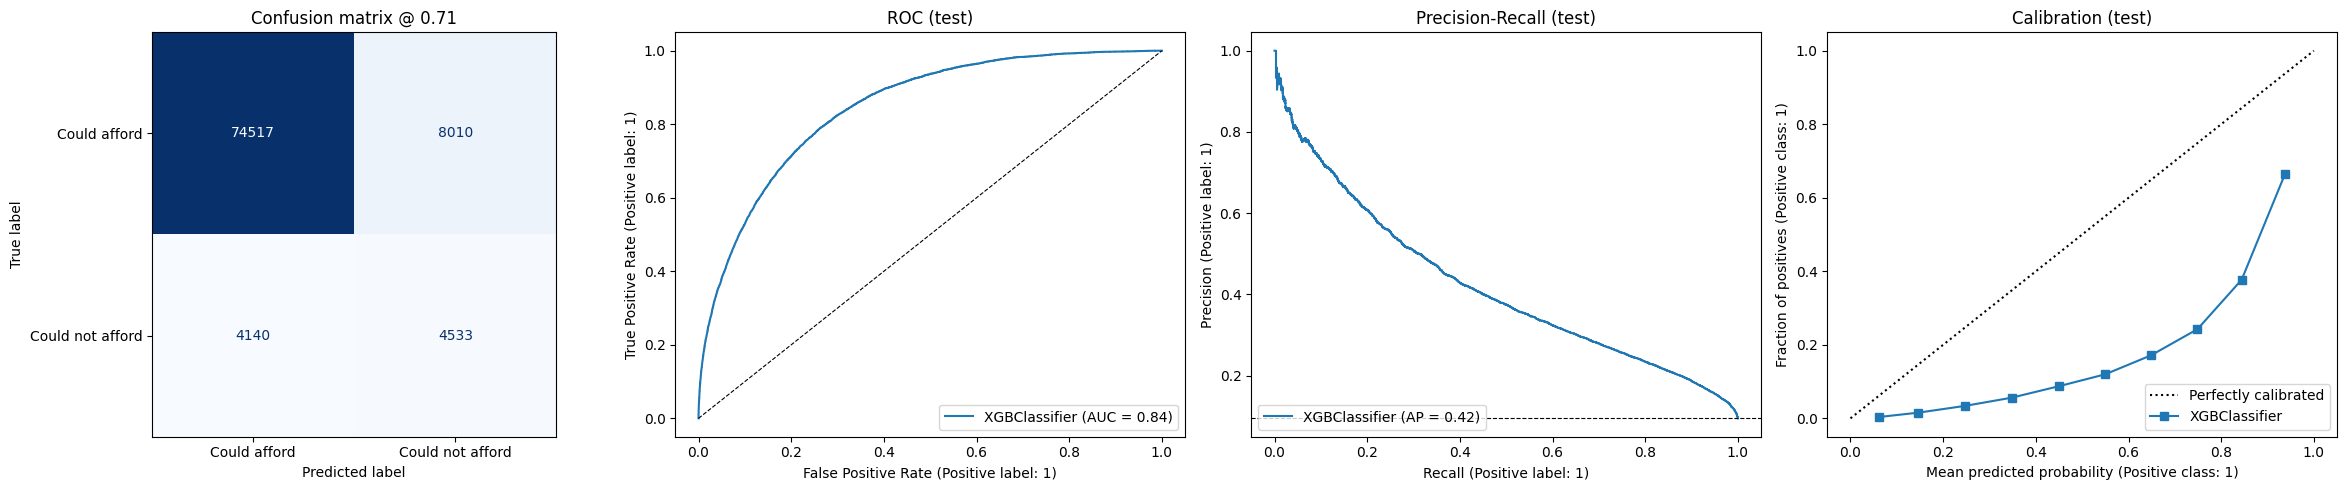

In [41]:
yp = (p_test >= best_th).astype(int)
print(classification_report(y_test, yp, target_names=['Could afford (0)', 'Could NOT afford (1)'], digits=4))
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
from sklearn.calibration import CalibrationDisplay
fig, ax = plt.subplots(1, 4, figsize=(24, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, yp), display_labels=['Could afford', 'Could not afford']).plot(ax=ax[0], colorbar=False, cmap='Blues')
ax[0].set_title(f'Confusion matrix @ {best_th}')
RocCurveDisplay.from_predictions(y_test, p_test, ax=ax[1], name=name_map[best_key]); ax[1].plot([0,1],[0,1],'k--',lw=.8); ax[1].set_title('ROC (test)')
PrecisionRecallDisplay.from_predictions(y_test, p_test, ax=ax[2], name=name_map[best_key]); ax[2].axhline(y_test.mean(), ls='--', c='k', lw=.8); ax[2].set_title('Precision-Recall (test)')
CalibrationDisplay.from_predictions(y_test, p_test, n_bins=10, ax=ax[3], name=name_map[best_key]); ax[3].set_title('Calibration (test)')
plt.tight_layout(); plt.show()

**Final model: XGBoost** (200 trees, max_depth 3, learning_rate 0.1, min_child_weight 3, class-weighted), selected by CV ROC-AUC (0.839 vs RF 0.831, KNN 0.730), then retrained on all 364,797 training rows.

| Test set (91,200 real rows) | ROC-AUC | PR-AUC | Precision (Yes) | Recall (Yes) | F1 (Yes) |
|---|---|---|---|---|---|
| Unweighted, threshold 0.71 | **0.845** | 0.418 | 0.361 | 0.523 | 0.427 |
| **Survey-weighted**, threshold 0.71 | **0.833** | **0.455** | 0.372 | 0.578 | 0.453 |

* PR-AUC 0.418 is **4.4×** the no-skill baseline (prevalence 0.095).
* Test ROC-AUC (0.845) is close to CV (0.839), so there are **no signs of overfitting**.
* **Threshold trade-off:** at 0.5 the model catches 77% of people with a cost barrier, but only 25% of flagged people truly have one. At the F1-optimal 0.71, it catches 52% with 36% precision. For outreach programmes, the right threshold depends on the cost of reaching someone. A paper should report both points or a full curve.
* **Calibration:** predicted probabilities are much **too high** (the curve sits under the diagonal). That is a side effect of class weighting. Rankings and AUC are fine, but the raw probabilities must not be read as risks. If probabilities are needed, add `CalibratedClassifierCV` (Platt or isotonic) as an extension.

# STEP 18 · Fairness check
> **What:** Measure performance separately for each group (race/ethnicity, income, rural/urban, sex, age, Medicaid expansion, insurance).  
> **Why here:** A model that works well on average can still fail some groups. We check after the final scores are known.  
> **Data after this step:** a table of scores by group

For each group on the test set: the survey-weighted prevalence, ROC-AUC, and, at the chosen threshold, **recall** (share of people with a cost barrier we catch) and **precision** (share of flagged people who really have one).
A large recall gap means the model systematically misses people in some groups.

In [42]:
T = X_test_raw.copy()
T['y'] = y_test; T['p'] = p_test; T['yp'] = yp; T['w'] = w_test
age_band = {'18-24':'18-34','25-29':'18-34','30-34':'18-34','35-39':'35-49','40-44':'35-49','45-49':'35-49',
            '50-54':'50-64','55-59':'50-64','60-64':'50-64','65-69':'65+','70-74':'65+','75-79':'65+','80+':'65+'}
T['age_band'] = T['age_group'].map(age_band).fillna('Unknown')

def subgroup_table(col):
    rows = []
    for g, d in T.groupby(col):
        if d.y.sum() < 30: continue
        rows.append({'group': f'{col} = {g}', 'n': len(d),
                     '% Yes (weighted)': 100 * np.average(d.y, weights=d.w),
                     'ROC-AUC': roc_auc_score(d.y, d.p, sample_weight=d.w),
                     'Recall': recall_score(d.y, d.yp, sample_weight=d.w),
                     'Precision': precision_score(d.y, d.yp, sample_weight=d.w, zero_division=0)})
    return pd.DataFrame(rows)

fair = pd.concat([subgroup_table(c) for c in ['race_ethnicity', 'income', 'urban_rural', 'sex', 'age_band',
                                              'medicaid_expansion_state', 'insurance_type']], ignore_index=True)
fair.round(3)

,group,n,% Yes (weighted),ROC-AUC,Recall,Precision
0,race_ethnicity = Black NH,6965,14.968,0.793,0.517,0.391
1,race_ethnicity = Hispanic,9737,19.215,0.792,0.731,0.369
2,race_ethnicity = Multiracial NH,2075,18.223,0.793,0.560,0.438
3,race_ethnicity = Other race NH,4969,10.583,0.799,0.474,0.336
4,race_ethnicity = Unknown,1698,18.416,0.780,0.578,0.415
5,race_ethnicity = White NH,65756,8.594,0.852,0.502,0.367
6,income = $100k-<200k,16584,5.433,0.779,0.193,0.384
7,income = $15k-<25k,6633,24.211,0.781,0.719,0.416
8,income = $200k+,5931,2.256,0.844,0.301,0.564
9,income = $25k-<35k,8322,18.202,0.806,0.712,0.356


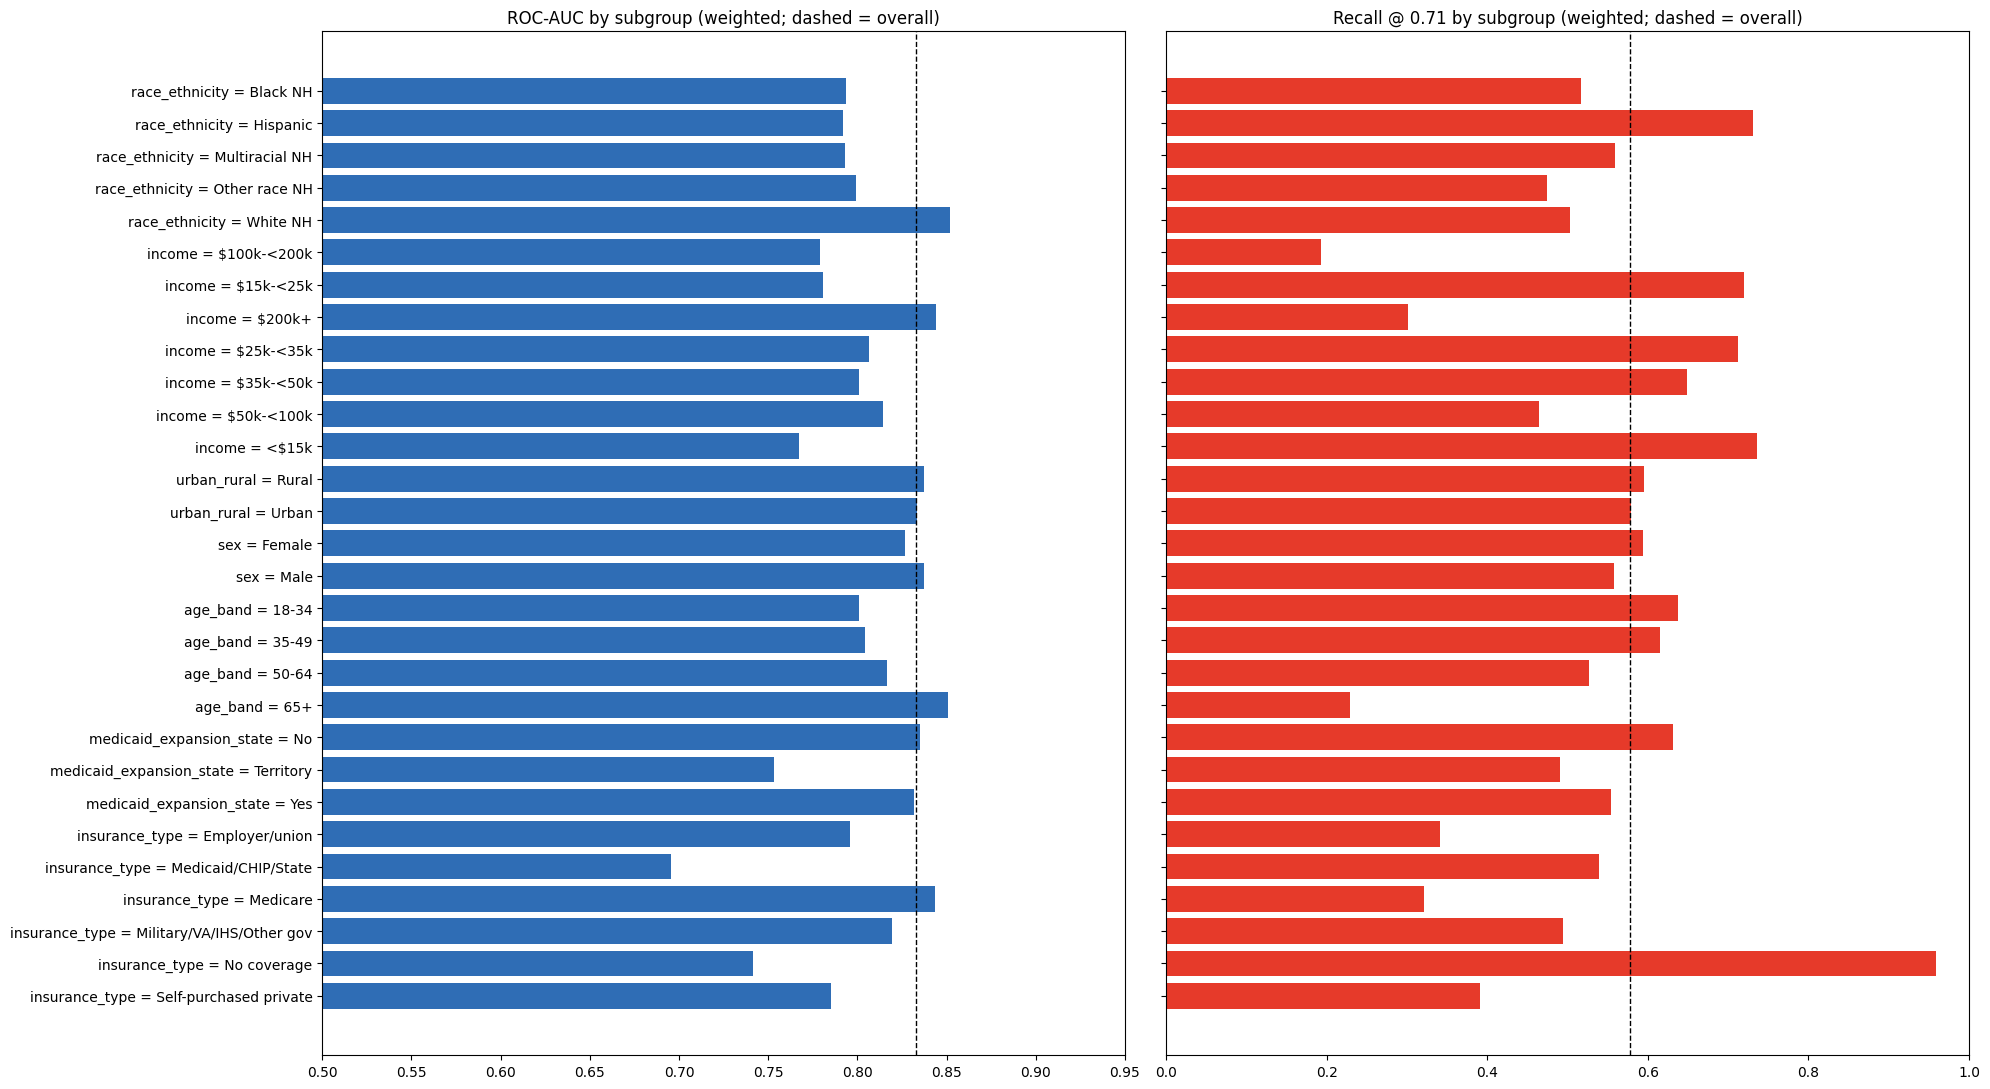

In [43]:
fig, ax = plt.subplots(1, 2, figsize=(20, 11), sharey=True)
f = fair[~fair.group.str.endswith('Unknown')].iloc[::-1]
ax[0].barh(f.group, f['ROC-AUC'], color='#2f6db5'); ax[0].axvline(summarize(best_th, w_test)['ROC-AUC'], c='k', ls='--', lw=1)
ax[0].set_title('ROC-AUC by subgroup (weighted; dashed = overall)'); ax[0].set_xlim(0.5, 0.95)
ax[1].barh(f.group, f['Recall'], color='#e63a2a'); ax[1].axvline(summarize(best_th, w_test)['Recall (Yes)'], c='k', ls='--', lw=1)
ax[1].set_title(f'Recall @ {best_th} by subgroup (weighted; dashed = overall)'); ax[1].set_xlim(0, 1)
plt.tight_layout(); plt.show()

**Report (weighted, test set)**

*Discrimination (ROC-AUC within each group):*
* AUC is lower inside several groups than overall (0.833): **Medicaid/CHIP/State 0.696**, No coverage 0.742, Hispanic 0.792, Black NH 0.793, Multiracial NH 0.793, versus **White NH 0.852**.
* Part of this is expected: inside one insurance group, insurance can no longer separate people, so within-group AUC naturally drops.
* The **~0.06 AUC gap between White NH and other race/ethnicity groups** is a real finding to report, and it should be investigated further.

*Recall at the 0.71 threshold:*
* Recall is **very uneven**: 96% for the uninsured, 73% for Hispanic adults, but only **23% for adults 65+**, **19% for $100k–<200k income**, 32% for Medicare and 34% for employer-insured.
* This happens because one global threshold flags mostly people from high-prevalence groups. People with a cost barrier inside *low-prevalence* groups (older, higher-income, insured) are largely missed.
* This is the "hidden" population a paper should highlight: cost barriers **despite** insurance or middle income.

*Little difference:* urban vs rural (AUC 0.833 vs 0.838; recall 0.58 vs 0.60) and sex (0.838 vs 0.827).

**Paper implication:** report subgroup metrics, and consider group-aware thresholds or a separate model for insured/older adults as an extension.

# STEP 19 · Explain the model (SHAP)
> **What:** Show which factors push a person's predicted risk up or down.  
> **Why here:** Decision-makers need to understand *why* the model predicts what it does.  
> **Data after this step:** a ranking of the most important factors

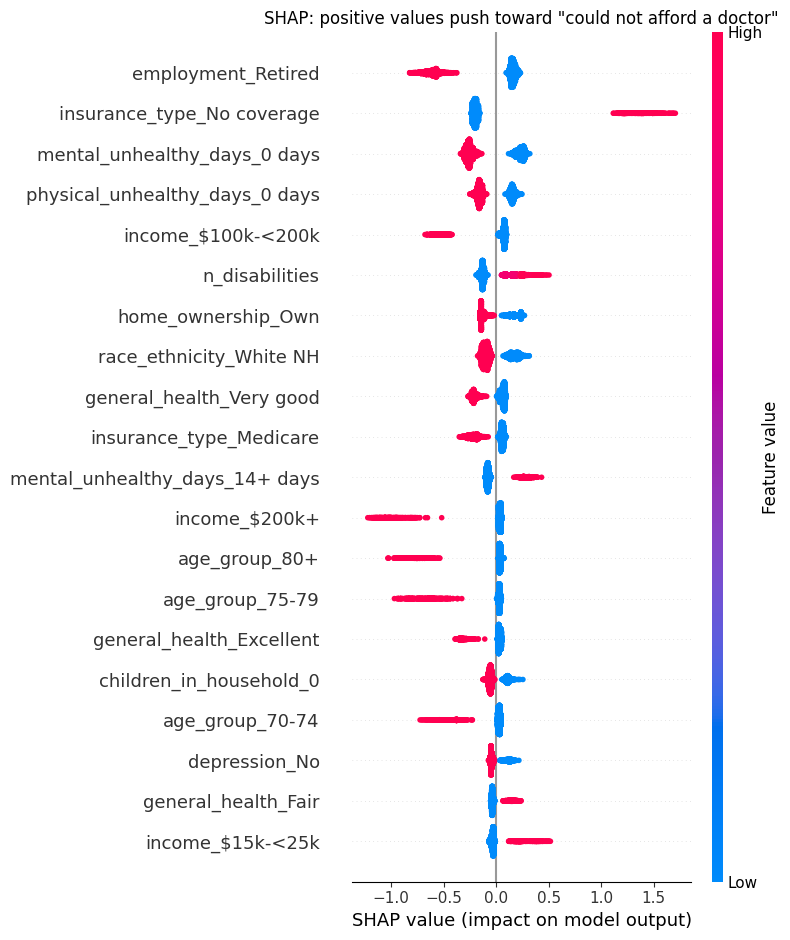

In [44]:
import shap
rng = np.random.RandomState(SEED)
sample = rng.choice(len(y_test), 5000, replace=False)
Xs = pd.DataFrame(X_test[sample], columns=feature_names)
if best_key in ('XGBoost', 'RF'):
    explainer = shap.TreeExplainer(best_model)
    sv = explainer.shap_values(Xs.values)   # numpy input: XGBoost rejects names containing '<' (e.g. income_<$15k)
    sv = sv[:, :, 1] if np.ndim(sv) == 3 else sv
    shap.summary_plot(sv, Xs, max_display=20, show=False)
    plt.title('SHAP: positive values push toward "could not afford a doctor"'); plt.tight_layout(); plt.show()

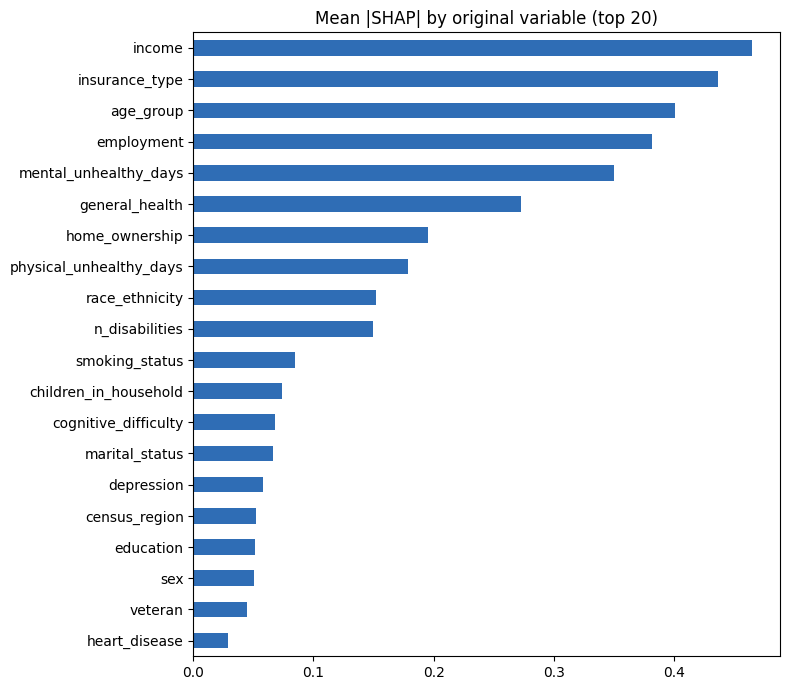

income                     0.4651
insurance_type             0.4364
age_group                  0.4013
employment                 0.3819
mental_unhealthy_days      0.3502
general_health             0.2731
home_ownership             0.1951
physical_unhealthy_days    0.1785
race_ethnicity             0.1518
n_disabilities             0.1499
smoking_status             0.0849
children_in_household      0.0734
cognitive_difficulty       0.0681
marital_status             0.0663
depression                 0.0583
census_region              0.0521
education                  0.0516
sex                        0.0505
veteran                    0.0446
heart_disease              0.0287
dtype: float32

In [45]:
# Group one-hot columns back to their original variable: mean |SHAP| per original feature
orig = [next((c for c in cat_features + num_features if fn == c or fn.startswith(c + '_')), fn) for fn in feature_names]
imp = pd.Series(np.abs(sv).mean(axis=0), index=orig).groupby(level=0).sum().sort_values()
imp.tail(20).plot(kind='barh', figsize=(8, 7), color='#2f6db5', title='Mean |SHAP| by original variable (top 20)')
plt.tight_layout(); plt.show()
imp.sort_values(ascending=False).round(4).head(20)

**Report**
* Grouped by original variable (mean |SHAP|), the top drivers are **income (0.47)**, **insurance type (0.44)**, **age (0.40)**, **employment (0.38)** and **mental unhealthy days (0.35)**. Next come general health, home ownership, physical unhealthy days, race/ethnicity and number of disabilities.
* The single strongest one-hot effect is **No coverage**, which pushes predictions up sharply. **Retired**, **Medicare**, ages **70+** and income **$200k+** push predictions strongly down.
* **Medicaid-expansion state, urban/rural and individual chronic conditions** are **not** among the top drivers once person-level factors are known. This matches the EDA (weak Cramér's V) and fits a "who you are and your coverage matter more than where you live" story. SHAP shows associations, not causes.

# STEP 20 · Save the model
> **What:** Save the preprocessor + model + threshold in one file.  
> **Why here:** So the model can be reused without retraining (Step 21).  
> **Data after this step:** `artifacts/brfss2024_cost_barrier_model.joblib`

**Save the final model** (preprocessor + model + threshold), so it can score new BRFSS-style records.

In [46]:
import joblib, os, json
os.makedirs("artifacts", exist_ok=True)
joblib.dump({"preprocessor": preprocessor, "model": best_model, "threshold": best_th,
             "features": cat_features + num_features, "target": "could_not_afford_doctor (1 = Yes)"},
            "artifacts/brfss2024_cost_barrier_model.joblib")
json.dump({"selected": name_map[best_key], "cv_auc": {k: float(v) for k, v in cv_score.items()},
           "params": {k: {p: (v if isinstance(v, (int, float, str)) or v is None else str(v)) for p, v in d.items()} for k, d in model_param.items()},
           "threshold": best_th, "test": final_table.round(4).to_dict(orient='index')},
          open("artifacts/training_summary.json", "w"), indent=2, default=str)
fair.round(4).to_csv("artifacts/fairness_subgroups.csv", index=False)
print("saved artifacts/")

saved artifacts/


# STEP 21 · Predict for one new person (requirement R13)
> **What:** Load the saved model and predict for one person from their 35 answers.  
> **Why here:** This is how the model would be used in practice.  
> **Data after this step:** a risk score and a Yes/No prediction

The saved model takes one person's answers (the same columns as the CSV) and returns:
* a **risk score** (0–1). Use it to *rank* people, not as a true probability, because the model isn't calibrated (see above);
* a **Yes/No prediction**, using the chosen threshold.

In [47]:
import joblib
import pandas as pd

bundle = joblib.load("artifacts/brfss2024_cost_barrier_model.joblib")

def predict_person(person: dict) -> dict:
    '''person: one record with the BRFSS columns (category labels as in BRFSS2024_access.csv).
    Missing answers can be given as "Unknown".'''
    row = pd.DataFrame([person])
    chronic = {'diabetes': 'Yes', 'heart_disease': 'Yes', 'stroke': 'Yes', 'copd': 'Yes', 'depression': 'Yes',
               'kidney_disease': 'Yes', 'arthritis': 'Yes', 'asthma': 'Current', 'cancer_non_skin': 'Yes'}
    dis = ['hearing_difficulty','vision_difficulty','cognitive_difficulty','mobility_difficulty',
           'selfcare_difficulty','independent_living_difficulty']
    row['n_chronic_conditions'] = sum((row[c] == v).astype(int) for c, v in chronic.items())
    row['n_disabilities'] = (row[dis] == 'Yes').sum(axis=1)
    X = bundle["preprocessor"].transform(row[bundle["features"]])
    score = float(bundle["model"].predict_proba(X)[0, 1])
    return {"risk_score": round(score, 3),
            "prediction": "Could NOT afford a doctor" if score >= bundle["threshold"] else "Could afford a doctor",
            "threshold": bundle["threshold"]}

In [48]:
base = dict(census_region="South", medicaid_expansion_state="No", urban_rural="Urban", sex="Female",
            race_ethnicity="Hispanic", education="High school graduate", marital_status="Never married",
            home_ownership="Rent", veteran="No", children_in_household="2", physical_activity="Yes",
            bmi_category="Overweight", smoking_status="Never", diabetes="No", heart_disease="No", stroke="No",
            copd="No", depression="No", kidney_disease="No", arthritis="No", asthma="Never", cancer_non_skin="No",
            hearing_difficulty="No", vision_difficulty="No", cognitive_difficulty="No", mobility_difficulty="No",
            selfcare_difficulty="No", independent_living_difficulty="No")

person_A = {**base, "age_group": "30-34", "income": "$15k-<25k", "employment": "Employed for wages",
            "insurance_type": "No coverage", "general_health": "Fair",
            "physical_unhealthy_days": "1-13 days", "mental_unhealthy_days": "14+ days"}
person_B = {**base, "age_group": "70-74", "income": "$100k-<200k", "employment": "Retired",
            "insurance_type": "Medicare", "general_health": "Very good", "medicaid_expansion_state": "Yes",
            "race_ethnicity": "White NH", "marital_status": "Married", "home_ownership": "Own",
            "children_in_household": "0", "physical_unhealthy_days": "0 days", "mental_unhealthy_days": "0 days"}

pd.DataFrame([{"person": "A: 30-34, uninsured, low income, poor mental health", **predict_person(person_A)},
              {"person": "B: 70-74, Medicare, high income, retired",           **predict_person(person_B)}])

,person,risk_score,prediction,threshold
0,"A: 30-34, uninsured, low income, poor mental h...",0.959,Could NOT afford a doctor,0.71
1,"B: 70-74, Medicare, high income, retired",0.032,Could afford a doctor,0.71


# ═════════ PART 2 · SHORT 12-QUESTION SCREENER ═════════

# STEP 22 · Choose the questions for the short screener
> **What:** Rank all features (training data only), exclude race/ethnicity, and test how many top features are needed.  
> **Why here:** Part 1 is done. Part 2 asks whether **far fewer questions** can give almost the same result.  
> **Data after this step:** **11 inputs = 12 survey questions**

**Why.** The full model needs 35 answers. That's fine for research, but too long for a real screening form, because people abandon long forms.
A practical public-health screener should take **under a minute** to fill in.

**How we choose the questions (no peeking at the test set):**
1. **Rank** the single-question features by their importance (mean |SHAP|) in a model trained on the **development data only**.
   * **Count real questions.** `n_disabilities` and `n_chronic_conditions` are built from 6 and 9 questions, so they are **not allowed** in the screener. Inputs built from 2 questions (smoking status, BMI category, asthma, heart disease) count as 2, and inputs that come from the person's state or county share one question each.
2. **Domain review.** `race_ethnicity` is **not** allowed as an input: a screener should not score people by race. We still *check* fairness by race afterwards.
3. **Test** nested subsets (top 3, top 4, … top 18) with 3-fold cross-validation on the development data.
4. **Rule:** use the **smallest** set whose CV ROC-AUC is within **0.005** of the full model.

In [49]:
from sklearn.model_selection import cross_val_score
from sklearn.metrics import brier_score_loss

# raw (readable) training rows: same split as before (same seed, same stratification)
Xtr_raw, Xte_raw, ytr_raw, yte_raw = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
assert (yte_raw == y_test).all() and (Xte_raw.index == X_test_raw.index).all()
Xdev_raw, ydev = Xtr_raw.iloc[dev_idx], ytr_raw[dev_idx]
xgb_params = dict(**model_param['XGBoost'], random_state=SEED, n_jobs=-1)   # tuned settings from Part 1

def make_pipe(cols, class_weight=True, y_fit=None):
    y_fit = ydev if y_fit is None else y_fit
    cats = [c for c in cols if c in cat_features]; nums = [c for c in cols if c in num_features]
    steps = [("OneHotEncoder", OneHotEncoder(handle_unknown='ignore', sparse_output=False), cats)]
    if nums: steps.append(("Transformer", PowerTransformer(method='yeo-johnson'), nums))
    spw_ = (y_fit == 0).sum() / (y_fit == 1).sum() if class_weight else 1.0
    return Pipeline([("pre", ColumnTransformer(steps)), ("model", XGBClassifier(**xgb_params, scale_pos_weight=spw_))])

# How many survey QUESTIONS each input really needs (a screener's length is its number of questions)
COMPOSITES = ['n_disabilities', 'n_chronic_conditions']     # built from 6 and 9 questions -> not allowed in the screener
QUESTION_COST = {'smoking_status': 2, 'bmi_category': 2, 'asthma': 2, 'heart_disease': 2}   # each built from 2 questions
SHARED = {'census_region': 'state', 'medicaid_expansion_state': 'state', 'urban_rural': 'county'}  # from place of residence
def n_questions(cols):
    places = {SHARED[c] for c in cols if c in SHARED}
    return sum(QUESTION_COST.get(c, 1) for c in cols if c not in SHARED) + len(places)

# 1) rank the single-question features on DEVELOPMENT data only
all_cols = cat_features + num_features
single_cols = [c for c in all_cols if c not in COMPOSITES]
rank_pipe = make_pipe(single_cols).fit(Xdev_raw, ydev)
Zd = rank_pipe['pre'].transform(Xdev_raw)
names = [n.split('__', 1)[1] for n in rank_pipe['pre'].get_feature_names_out()]
sv_dev = shap.TreeExplainer(rank_pipe['model']).shap_values(Zd)
orig = [next(c for c in sorted(single_cols, key=len, reverse=True) if n == c or n.startswith(c + '_')) for n in names]
dev_rank = pd.Series(np.abs(sv_dev).mean(axis=0), index=orig).groupby(level=0).sum().sort_values(ascending=False)

# 2) domain review: race/ethnicity is not allowed as an input
candidates = [c for c in dev_rank.index if c != 'race_ethnicity']
dev_rank.round(4).head(15)

income                     0.5313
insurance_type             0.4304
age_group                  0.4192
employment                 0.3884
mental_unhealthy_days      0.3700
general_health             0.2594
home_ownership             0.2110
physical_unhealthy_days    0.1608
race_ethnicity             0.1452
smoking_status             0.1246
cognitive_difficulty       0.1085
marital_status             0.0803
census_region              0.0613
mobility_difficulty        0.0587
asthma                     0.0574
dtype: float32

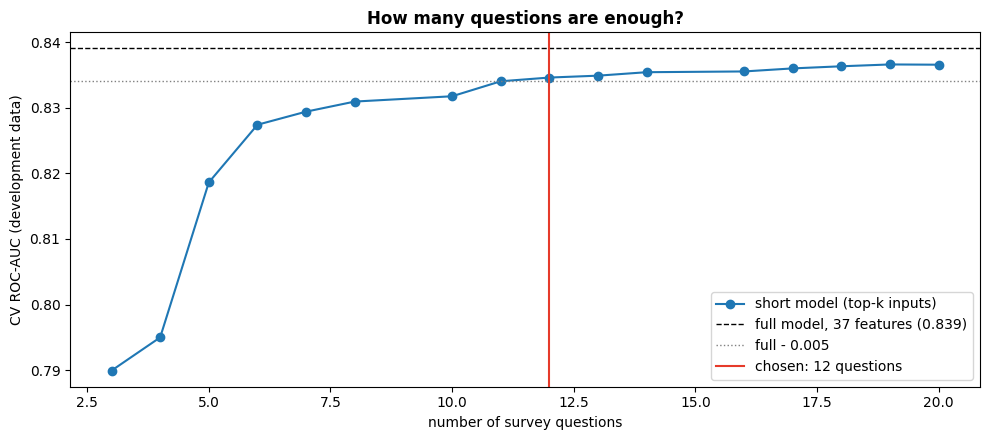

Full model CV AUC 0.8390 | chosen k = 11 inputs = 12 questions, CV AUC 0.8346
Short-model inputs: ['income', 'insurance_type', 'age_group', 'employment', 'mental_unhealthy_days', 'general_health', 'home_ownership', 'physical_unhealthy_days', 'smoking_status', 'cognitive_difficulty', 'marital_status']


,questions,added,cv_auc
k,,,
3,3,age_group,0.7899
4,4,employment,0.7950
5,5,mental_unhealthy_days,0.8186
6,6,general_health,0.8274
7,7,home_ownership,0.8294
8,8,physical_unhealthy_days,0.8309
9,10,smoking_status,0.8318
10,11,cognitive_difficulty,0.8340
11,12,marital_status,0.8346


In [50]:
# 3) nested subsets, 3-fold CV on development data; x-axis = number of survey QUESTIONS
full_cv = cross_val_score(make_pipe(all_cols), Xdev_raw, ydev, cv=cv, scoring='roc_auc').mean()
curve = pd.DataFrame([{'k': k, 'questions': n_questions(candidates[:k]), 'added': candidates[k-1],
                       'cv_auc': cross_val_score(make_pipe(candidates[:k]), Xdev_raw, ydev, cv=cv, scoring='roc_auc').mean()}
                      for k in range(3, 19)]).set_index('k')

# 4) rule: smallest set within 0.005 of the full model
TOL = 0.005
k_star = int(curve.index[curve['cv_auc'] >= full_cv - TOL].min())
short_features = candidates[:k_star]
n_q = n_questions(short_features)

plt.figure(figsize=(10, 4.5))
plt.plot(curve['questions'], curve['cv_auc'], 'o-', label='short model (top-k inputs)')
plt.axhline(full_cv, c='k', ls='--', lw=1, label=f'full model, 37 features ({full_cv:.3f})')
plt.axhline(full_cv - TOL, c='grey', ls=':', lw=1, label=f'full - {TOL}')
plt.axvline(n_q, c='#e63a2a', lw=1.5, label=f'chosen: {n_q} questions')
plt.xlabel('number of survey questions'); plt.ylabel('CV ROC-AUC (development data)'); plt.legend()
plt.title('How many questions are enough?', weight='bold'); plt.tight_layout(); plt.show()
print(f"Full model CV AUC {full_cv:.4f} | chosen k = {k_star} inputs = {n_q} questions, CV AUC {curve.loc[k_star, 'cv_auc']:.4f}")
print("Short-model inputs:", short_features)
curve.round(4)

**Result: 11 inputs (12 survey questions) are enough**
* Development-data CV ROC-AUC: **0.835 with 12 questions** vs **0.839 with all 37 features**, a loss of 0.004 (within the 0.005 rule).
* With 11 questions (dropping marital status) the CV ROC-AUC is 0.834, just below the cut-off, so the rule picks 12. Beyond 12 the curve is almost flat. Below 6 questions, accuracy drops quickly.
* **The 12 questions:** income, insurance type, age group, employment, poor mental-health days, general health, home ownership, poor physical-health days, smoking status (2 questions: ever smoked 100 cigarettes; smoke now), serious difficulty concentrating/remembering/deciding, marital status.
* In the earlier version, the 10th input was `n_disabilities`, which needs **6 questions**. Counting real questions replaced it with the single cognitive-difficulty question.
* **Domain check:** every question is a standard, easy-to-answer survey item, and none needs a lab test or medical record. Race/ethnicity ranked 9th but was excluded on purpose.
* Smoking status is not a medical cause of cost barriers. It most likely acts as a **marker of social and economic disadvantage**, and the paper should say so.

# STEP 23 · Class weights or not? (realistic risk percentages)
> **What:** Compare the short model with and without class weights, looking at calibration (Brier score).  
> **Why here:** The questions are fixed (Step 22). Now we decide how to train the model so its risk % can be trusted.  
> **Data after this step:** decision: **unweighted** (calibrated)

Part 1 showed that class weighting pushes probabilities far too high. A screener that says "your risk is 70%" should mean roughly 70%.
We compare both options on development data (out-of-fold). If ROC-AUC is about the same (within 0.002), we keep the option with the lower **Brier score**, i.e. the better-calibrated one.

In [51]:
rows, oof_s = [], {}
for lab, cw in [('class-weighted', True), ('unweighted', False)]:
    o = cross_val_predict(make_pipe(short_features, cw), Xdev_raw, ydev, cv=cv, method='predict_proba')[:, 1]
    oof_s[lab] = o
    rows.append({'option': lab, 'ROC-AUC': roc_auc_score(ydev, o), 'PR-AUC': average_precision_score(ydev, o),
                 'Brier (lower = better)': brier_score_loss(ydev, o), 'mean predicted risk': o.mean(), 'true rate': ydev.mean()})
calib_tab = pd.DataFrame(rows).set_index('option')
use_weights = not (calib_tab.loc['unweighted', 'ROC-AUC'] >= calib_tab.loc['class-weighted', 'ROC-AUC'] - 0.002
                   and calib_tab.loc['unweighted', 'Brier (lower = better)'] < calib_tab.loc['class-weighted', 'Brier (lower = better)'])
chosen = 'class-weighted' if use_weights else 'unweighted'
print("Chosen:", chosen)
calib_tab.round(4)

Chosen: unweighted


,ROC-AUC,PR-AUC,Brier (lower = better),mean predicted risk,true rate
option,,,,,
class-weighted,0.8345,0.4074,0.1632,0.3555,0.0951
unweighted,0.8349,0.4085,0.0696,0.0951,0.0951


# STEP 24 · Train the short screener and take the final exam
> **What:** Set its threshold (from cross-validation), train on all training rows, then compare with the full model on the test set.  
> **Why here:** Questions (Step 22) and training method (Step 23) are fixed.  
> **Data after this step:** final scores for both models side by side

In [52]:
# threshold for the short model: maximise out-of-fold F1 on development data
ths_s = np.round(np.arange(0.05, 0.96, 0.01), 2)
th_short = float(ths_s[int(np.argmax([f1_score(ydev, oof_s[chosen] >= t) for t in ths_s]))])

# final short model: retrain on the FULL training set, then score the untouched test set once
short_model = make_pipe(short_features, use_weights, y_fit=ytr_raw).fit(Xtr_raw[short_features], ytr_raw)
p_short = short_model.predict_proba(Xte_raw[short_features])[:, 1]
print(f"Short model ({len(short_features)} inputs, {chosen}) | threshold = {th_short}")

Short model (11 inputs, unweighted) | threshold = 0.22


In [53]:
def scorecard(p, th, wts=None):
    yp_ = (p >= th).astype(int)
    return {'ROC-AUC': roc_auc_score(y_test, p, sample_weight=wts), 'PR-AUC': average_precision_score(y_test, p, sample_weight=wts),
            'Recall (Yes)': recall_score(y_test, yp_, sample_weight=wts), 'Precision (Yes)': precision_score(y_test, yp_, sample_weight=wts),
            'F1 (Yes)': f1_score(y_test, yp_, sample_weight=wts), 'Brier': brier_score_loss(y_test, p, sample_weight=wts),
            'threshold': th}
compare_models = pd.DataFrame({
    f'Full model (37 features) - unweighted': scorecard(p_test, best_th),
    f'Short model ({len(short_features)} inputs) - unweighted': scorecard(p_short, th_short),
    f'Full model - survey-weighted': scorecard(p_test, best_th, w_test),
    f'Short model - survey-weighted': scorecard(p_short, th_short, w_test),
}).T
compare_models.round(4)

,ROC-AUC,PR-AUC,Recall (Yes),Precision (Yes),F1 (Yes),Brier,threshold
Full model (37 features) - unweighted,0.8450,0.4184,0.5227,0.3614,0.4273,0.1625,0.71
Short model (11 inputs) - unweighted,0.8394,0.4072,0.4806,0.3726,0.4197,0.0696,0.22
Full model - survey-weighted,0.8327,0.4550,0.5782,0.3720,0.4527,0.1967,0.71
Short model - survey-weighted,0.8272,0.4444,0.5261,0.4012,0.4552,0.0846,0.22


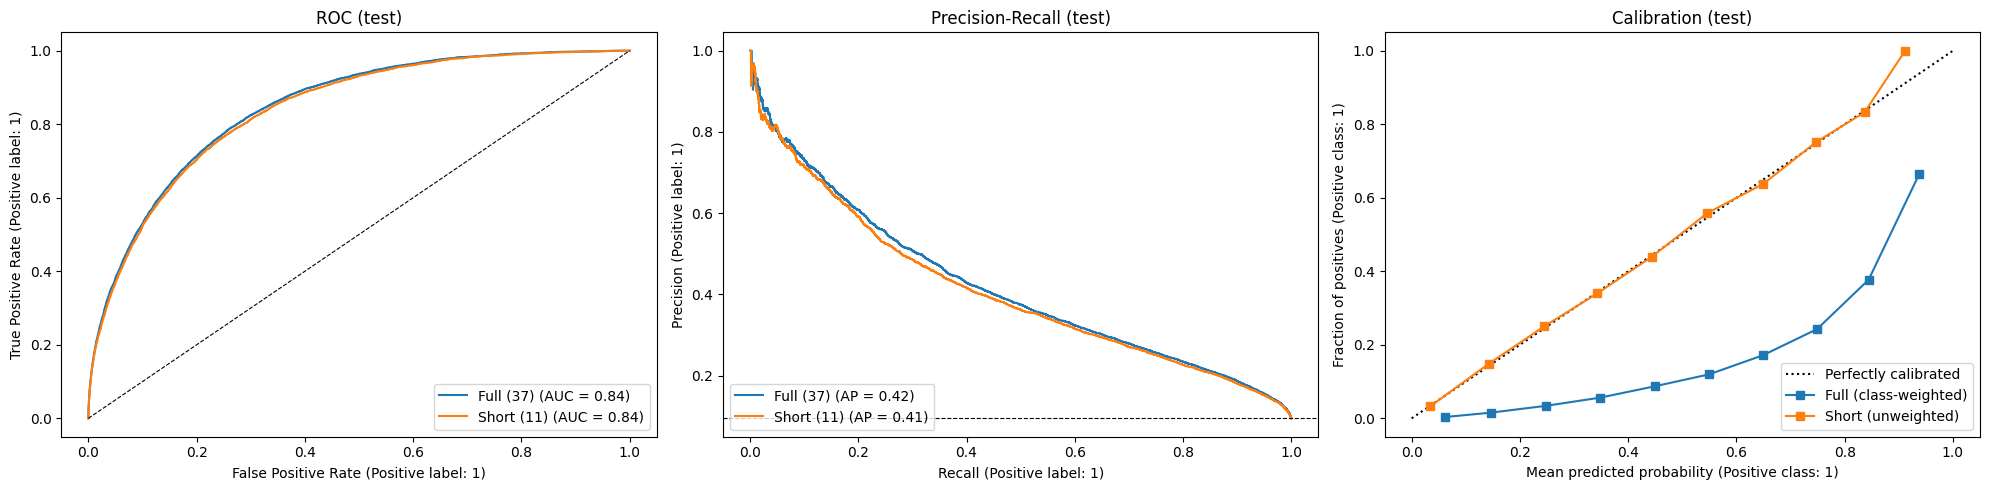

In [54]:
from sklearn.calibration import CalibrationDisplay
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
RocCurveDisplay.from_predictions(y_test, p_test, ax=ax[0], name='Full (37)')
RocCurveDisplay.from_predictions(y_test, p_short, ax=ax[0], name=f'Short ({len(short_features)})'); ax[0].plot([0,1],[0,1],'k--',lw=.8); ax[0].set_title('ROC (test)')
PrecisionRecallDisplay.from_predictions(y_test, p_test, ax=ax[1], name='Full (37)')
PrecisionRecallDisplay.from_predictions(y_test, p_short, ax=ax[1], name=f'Short ({len(short_features)})'); ax[1].axhline(y_test.mean(), c='k', ls='--', lw=.8); ax[1].set_title('Precision-Recall (test)')
CalibrationDisplay.from_predictions(y_test, p_test, n_bins=10, ax=ax[2], name='Full (class-weighted)')
CalibrationDisplay.from_predictions(y_test, p_short, n_bins=10, ax=ax[2], name=f'Short ({chosen})'); ax[2].set_title('Calibration (test)')
plt.tight_layout(); plt.show()

**Result on the untouched test set (91,200 people)**

| | Full model (37 features from 35 answers) | **Short screener (12 questions)** |
|---|---|---|
| ROC-AUC | 0.845 | **0.839** |
| ROC-AUC, survey-weighted | 0.833 | **0.827** |
| PR-AUC | 0.418 | **0.407** |
| Brier score (calibration error, lower = better) | 0.163 | **0.070** |
| Precision / Recall at its threshold | 0.36 / 0.52 | 0.36 / 0.50 |

* With **12 questions instead of 35 answers (66% fewer)**, the screener loses only **0.006 ROC-AUC**.
* It is **much better calibrated**: its curve sits on the diagonal. A predicted risk of 40% really means about 40 in 100. The full, class-weighted model overstates risk.
* Lesson: class weights help a model *rank* people, but they distort the probabilities. For a screening tool, train unweighted and handle the imbalance with the **threshold** (0.21 here).

# STEP 25 · Fairness of the short screener
> **What:** Repeat the group check for the 12-question model and compare it with the full model.  
> **Why here:** Removing questions (including race) could change fairness, so we must check.  
> **Data after this step:** a side-by-side table by group

In [55]:
def subgroup_metrics(p, th, col):
    d0 = X_test_raw.assign(y=y_test, p=p, yp=(p >= th).astype(int), w=w_test)
    d0['age_band'] = d0['age_group'].map(age_band).fillna('Unknown')
    out = []
    for g, d in d0.groupby(col):
        if d.y.sum() < 30 or g == 'Unknown': continue
        out.append({'group': f'{col} = {g}', 'AUC': roc_auc_score(d.y, d.p, sample_weight=d.w),
                    'Recall': recall_score(d.y, d.yp, sample_weight=d.w)})
    return pd.DataFrame(out)
cols_f = ['race_ethnicity', 'income', 'urban_rural', 'sex', 'age_band', 'insurance_type']
fair_cmp = pd.concat([subgroup_metrics(p_test, best_th, c) for c in cols_f]).set_index('group').add_prefix('Full ') \
    .join(pd.concat([subgroup_metrics(p_short, th_short, c) for c in cols_f]).set_index('group').add_prefix('Short '))
fair_cmp['AUC change'] = fair_cmp['Short AUC'] - fair_cmp['Full AUC']
fair_cmp.round(3)

,Full AUC,Full Recall,Short AUC,Short Recall,AUC change
group,,,,,
race_ethnicity = Black NH,0.793,0.517,0.790,0.442,-0.004
race_ethnicity = Hispanic,0.792,0.731,0.793,0.644,0.000
race_ethnicity = Multiracial NH,0.793,0.560,0.771,0.466,-0.021
race_ethnicity = Other race NH,0.799,0.474,0.791,0.421,-0.009
race_ethnicity = White NH,0.852,0.502,0.847,0.493,-0.005
income = $100k-<200k,0.779,0.193,0.771,0.131,-0.008
income = $15k-<25k,0.781,0.719,0.781,0.667,-0.000
income = $200k+,0.844,0.301,0.824,0.326,-0.020
income = $25k-<35k,0.806,0.712,0.805,0.662,-0.001


**Report**
* Removing 26 inputs (including race/ethnicity) changes subgroup ROC-AUC very little: **most changes are within ±0.01**. The largest drops are income $200k+ (−0.025), Military/VA/Other gov insurance (−0.024) and Multiracial NH (−0.021).
* The **race/ethnicity gap is about the same** as in the full model (White NH 0.846 vs Black NH 0.790, Hispanic 0.792). Excluding race as an input neither caused nor fixed this gap; it comes from the other factors.
* The **low-recall problem remains**: adults 65+ (16%), income $100k–<200k (14%), Medicare (28%) and employer-insured (31%). People facing cost barriers *despite* insurance or higher income are the hardest to detect, and that is a key finding for the paper.

# STEP 26 · Explain the short screener (SHAP)
> **What:** Show what drives the 12-question model.  
> **Why here:** Same reason as Step 19.  
> **Data after this step:** a SHAP plot

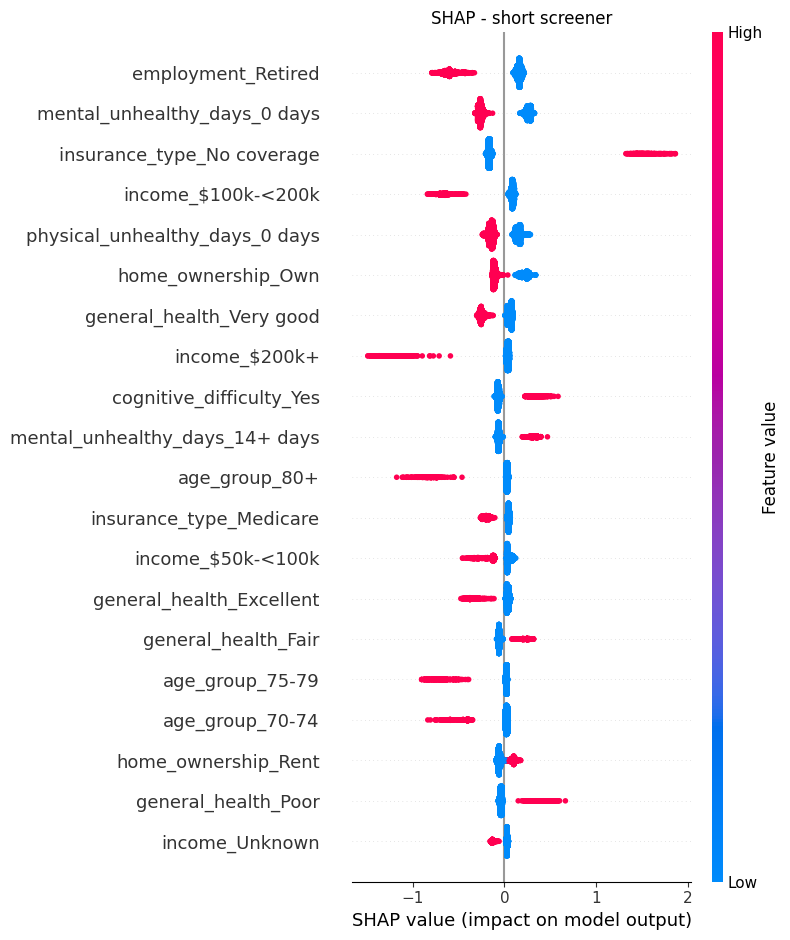

In [56]:
Zs = short_model['pre'].transform(Xte_raw[short_features].iloc[sample])
names_s = [n.split('__', 1)[1] for n in short_model['pre'].get_feature_names_out()]
sv_s = shap.TreeExplainer(short_model['model']).shap_values(Zs)
shap.summary_plot(sv_s, pd.DataFrame(Zs, columns=names_s), max_display=20, show=False)
plt.title('SHAP - short screener'); plt.tight_layout(); plt.show()

# STEP 27 · Save the short screener and predict for one person
> **What:** Save the 12-question model and predict from its 11 inputs.  
> **Why here:** This is the practical tool a user would fill in.  
> **Data after this step:** a risk % and a Yes/No prediction

In [57]:
joblib.dump({"model": short_model, "threshold": th_short, "features": short_features,
             "target": "could_not_afford_doctor (1 = Yes)", "calibrated": not use_weights, "n_questions": n_q},
            "artifacts/brfss2024_short_screener.joblib")

def predict_person_short(person: dict) -> dict:
    s = joblib.load("artifacts/brfss2024_short_screener.joblib")
    row = pd.DataFrame([{f: person.get(f, "Unknown") for f in s["features"]}])
    p = float(s["model"].predict_proba(row)[0, 1])
    return {"risk_%": round(100 * p, 1),
            "prediction": "Could NOT afford a doctor" if p >= s["threshold"] else "Could afford a doctor",
            "threshold": s["threshold"]}

print("Questions asked:", short_features)
person_A_short = {k: person_A[k] for k in short_features if k in person_A}
person_B_short = {k: person_B[k] for k in short_features if k in person_B}
pd.DataFrame([{"person": "A (uninsured, low income, poor mental health)", **predict_person_short(person_A_short)},
              {"person": "B (Medicare, high income, retired)", **predict_person_short(person_B_short)}])

Questions asked: ['income', 'insurance_type', 'age_group', 'employment', 'mental_unhealthy_days', 'general_health', 'home_ownership', 'physical_unhealthy_days', 'smoking_status', 'cognitive_difficulty', 'marital_status']


,person,risk_%,prediction,threshold
0,"A (uninsured, low income, poor mental health)",74.5,Could NOT afford a doctor,0.22
1,"B (Medicare, high income, retired)",0.4,Could afford a doctor,0.22


# STEP 28 · Conclusions
> **What:** Summarise the results, limitations and next steps.  
> **Why here:** All results are in.  
> **Data after this step:** —

**Main results (BRFSS 2024, n = 455,997; held-out test n = 91,200)**
1. **Full model:** a class-weighted XGBoost with 37 inputs reaches **ROC-AUC 0.845 (survey-weighted 0.833)** and **PR-AUC 0.418 (4.4× the baseline)**. A **logistic regression is nearly as good (cross-validated 0.837)**, an important honest benchmark.
2. **Short 12-question screener** (no race input, no composite counts, unweighted XGBoost): **ROC-AUC 0.839 (survey-weighted 0.827)**, PR-AUC 0.407, and **well-calibrated risks** (Brier 0.070 vs 0.163). It asks 12 questions instead of 35 (66% fewer) for a 0.006 loss in ROC-AUC, which makes it practical for real public-health use.
3. **Class weights vs SMOTEENN:** in cross-validation on the development data, class weights gave higher PR-AUC for every model tested. But class weighting distorts probabilities, so for a screener, train unweighted and set the threshold instead.
4. **Strongest drivers:** income, insurance type (especially no coverage), age (Medicare age is protective), employment and poor mental health. State Medicaid-expansion status and urban/rural add little once person-level factors are known.
5. **Fairness:** ROC-AUC is lower for Black, Hispanic and Multiracial adults (~0.78–0.79) than for White adults (~0.85), in both models. Recall is very low for older, insured and higher-income adults: people with cost barriers *despite* coverage are the hardest to detect.

**Limitations to state in the paper:**
* cross-sectional and self-reported data, so associations, not causation;
* the 2024 file excludes Tennessee and was modified per executive orders;
* `Unknown` kept as a category (income 19%);
* hyperparameters tuned on a 60k development subsample;
* survey weights used in evaluation but not in training;
* model comparison, the imbalance method, feature selection and thresholds use cross-validation on development data only, and the test set was used once.

**Possible extensions:**
* group-specific thresholds;
* complete-case sensitivity analysis;
* a sensitivity model adding `has_personal_doctor` / `last_checkup`;
* external validation on the 2025 BRFSS file;
* a simple web form for the 12-question screener.

# STEP 29 · Final result: which is the best model?
> **What:** Show both final models side by side and state the best one.  
> **Why here:** The last word, like the visa notebook.  
> **Data after this step:** —

In [58]:
final_summary = pd.DataFrame({
    'Full model: XGBoost, 37 features': {**scorecard(p_test, best_th), 'Accuracy': accuracy_score(y_test, (p_test >= best_th).astype(int))},
    f'Short screener: XGBoost, {len(short_features)} questions': {**scorecard(p_short, th_short), 'Accuracy': accuracy_score(y_test, (p_short >= th_short).astype(int))},
}).T[['Accuracy', 'ROC-AUC', 'PR-AUC', 'Precision (Yes)', 'Recall (Yes)', 'F1 (Yes)', 'Brier', 'threshold']]
print("Baseline accuracy if the model always says 'No':", round(1 - y_test.mean(), 4))
final_summary.round(4)

Baseline accuracy if the model always says 'No': 0.9049


,Accuracy,ROC-AUC,PR-AUC,Precision (Yes),Recall (Yes),F1 (Yes),Brier,threshold
"Full model: XGBoost, 37 features",0.8668,0.8450,0.4184,0.3614,0.5227,0.4273,0.1625,0.71
"Short screener: XGBoost, 11 questions",0.8736,0.8394,0.4072,0.3726,0.4806,0.4197,0.0696,0.22


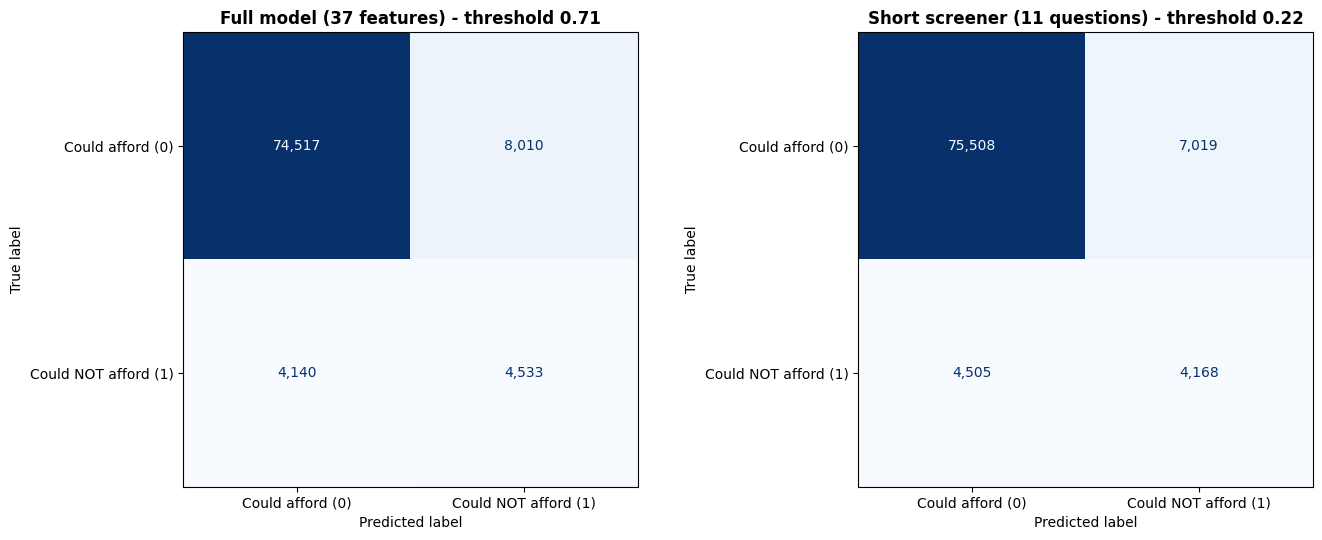

                      precision    recall  f1-score   support

    Could afford (0)     0.9437    0.9149    0.9291     82527
Could NOT afford (1)     0.3726    0.4806    0.4197      8673

            accuracy                         0.8736     91200
           macro avg     0.6581    0.6978    0.6744     91200
        weighted avg     0.8894    0.8736    0.8807     91200



In [59]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for a, (p, th, title) in zip(ax, [(p_test, best_th, 'Full model (37 features)'),
                                  (p_short, th_short, f'Short screener ({len(short_features)} questions)')]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (p >= th).astype(int)),
                           display_labels=['Could afford (0)', 'Could NOT afford (1)']).plot(ax=a, colorbar=False, cmap='Blues', values_format=',')
    a.set_title(f'{title} - threshold {th}', weight='bold')
plt.tight_layout(); plt.show()
print(classification_report(y_test, (p_short >= th_short).astype(int),
                            target_names=['Could afford (0)', 'Could NOT afford (1)'], digits=4))

## Best Model is XGBoost (Extreme Gradient Boosting) with ROC-AUC 0.845

* **Why XGBoost won:** it had the highest cross-validation ROC-AUC among the tuned models: **XGBoost 0.839**, Random Forest 0.831, KNN 0.730. It was chosen on cross-validation, not on the final exam.
* **Final exam (91,200 people the model never saw):**

| Version | Inputs | ROC-AUC | Accuracy | Recall (Yes) | Use |
|---|---|---|---|---|---|
| **Full XGBoost** | 37 features (35 answers) | **0.845** | 86.7% | 52.3% | Best accuracy, the research benchmark |
| **Short XGBoost screener** | **12 questions** | **0.839** | 86.9% | 50.3% | ⭐ **Recommended for real use**: 12 questions, realistic risk % |

* **Note on accuracy:** 87% looks *lower* than the 90.5% "always say No" baseline. That is expected and correct. The baseline never finds a single person with a cost barrier, while our model finds about **half of them**, ranking people far better than chance (ROC-AUC 0.84 vs 0.50).